# 02 · EDA básico — Competencia crediticia

Análisis exploratorio de datos (EDA) del conjunto de la competencia. Cada
sección plantea una pregunta, presenta la evidencia y cierra con una lectura
de los resultados. El documento es autocontenido: define sus términos y no
requiere otros notebooks para seguirse.

**Objetivo del modelo:** predecir la probabilidad de que un cliente tenga
morosidad grave (90 días o más de atraso) en los próximos 2 años.
**Métrica:** AUC-ROC.

**Temas de experimentación de la competencia y sección que los cubre:**

| Tema | Sección |
| --- | --- |
| Calidad de datos (duplicados) | Sección 1 |
| Valores faltantes y atípicos | Secciones 5, 7 y 10 |
| Monto mensual de deuda (detalle) | Sección 10.3 e |
| Influencia de los dependientes | Sección 10.3 f |
| Ingeniería y selección de variables | Secciones 8 y 9 |
| Escalado y preparación de variables | Sección 10 |
| Algoritmos de clasificación | Sección 11 (desbalance) |
| Regularización, validación cruzada, hiperparámetros | Sección 11 |

## 0. Preparación
Carga de librerías y datos. Los archivos se leen de `data/raw/` y se
descargan con `PYTHONPATH=src uv run python -m etl.download`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
train = pd.read_csv(ROOT / "data/raw/train.csv")
test = pd.read_csv(ROOT / "data/raw/test.csv")

TARGET = "SeriousDlqin2yrs"
ID = "Id"
FEATS = [c for c in train.columns if c not in (TARGET, ID)]

## 1. Ordenamiento y registros duplicados
Antes de explorar se revisa la **calidad básica** del conjunto de datos:
¿hay registros repetidos?

**Criterio de eliminación:** solo se elimina una fila si su `Id` está
repetido (el mismo registro cargado dos veces). Las filas con `Id` distinto se
conservan aunque su contenido sea idéntico, porque pueden ser clientes
distintos con el mismo perfil; esas solo se **reportan**.

Primero se ordenan los datos:
- Por `Id`, para tener un orden estable y reproducible.
- Por todas las variables, para que los registros iguales queden juntos y se
  puedan revisar a simple vista.

In [2]:
train = train.sort_values(ID).reset_index(drop=True)
test = test.sort_values(ID).reset_index(drop=True)

# Orden por todas las columnas: los registros idénticos quedan contiguos
train_ordenado = train.sort_values(FEATS + [TARGET], na_position="last")
train_ordenado.head()

,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
94080,134366,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
95976,137103,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
32028,45616,0,0.0,21,0,0.0,1.0,1,0,0,0,0.0
85812,122511,0,0.0,21,0,0.0,1.0,2,0,0,0,0.0
45297,64512,0,0.0,21,0,0.0,240.0,1,0,0,0,0.0


Se revisan tres tipos de duplicado:

| Tipo | Definición | Acción |
| --- | --- | --- |
| Por `Id` | El mismo `Id` aparece más de una vez | **Se elimina** la copia |
| Mismo contenido | Mismas variables y mismo objetivo, distinto `Id` | Se reporta, se conserva |
| En conflicto | Mismas variables pero objetivo distinto | Se reporta, se conserva |

In [3]:
dup_id = train[ID].duplicated()
dup_exacto = train.duplicated(subset=FEATS + [TARGET], keep="first")
dup_variables = train.duplicated(subset=FEATS, keep=False)
grupos_conflicto = (
    train[dup_variables]
    .groupby(FEATS, dropna=False)[TARGET]
    .nunique()
    .gt(1)
    .sum()
)

resumen_dup = pd.DataFrame(
    {
        "registros": [
            dup_id.sum(),
            dup_exacto.sum(),
            train.duplicated(subset=FEATS + [TARGET], keep=False).sum(),
            grupos_conflicto,
        ]
    },
    index=[
        "Id repetidos",
        "Mismo contenido con distinto Id (copias)",
        "Filas involucradas en contenido repetido",
        "Grupos en conflicto (mismo perfil, objetivo distinto)",
    ],
)
resumen_dup

,registros
Id repetidos,0
Mismo contenido con distinto Id (copias),339
Filas involucradas en contenido repetido,562
"Grupos en conflicto (mismo perfil, objetivo distinto)",26


### Notificación

In [4]:
n_dup_id = int(dup_id.sum())
n_dup_contenido = int(dup_exacto.sum())
if n_dup_id > 0:
    print(f"⚠️ Hay {n_dup_id:,} Id repetidos: se eliminarán las copias.")
else:
    print("✅ No hay Id repetidos: no se elimina ninguna fila.")

if n_dup_contenido > 0:
    pct = n_dup_contenido / len(train) * 100
    print(
        f"ℹ️ Hay {n_dup_contenido:,} registros con el mismo contenido y distinto Id "
        f"({pct:.2f} % de train). Se conservan porque su Id no se repite."
    )

if grupos_conflicto > 0:
    print(
        f"ℹ️ {grupos_conflicto} grupos tienen el mismo perfil con objetivo distinto. "
        "No se eliminan (ambos resultados son reales), pero son ruido para el modelo."
    )

✅ No hay Id repetidos: no se elimina ninguna fila.
ℹ️ Hay 339 registros con el mismo contenido y distinto Id (0.32 % de train). Se conservan porque su Id no se repite.
ℹ️ 26 grupos tienen el mismo perfil con objetivo distinto. No se eliminan (ambos resultados son reales), pero son ruido para el modelo.


In [5]:
# Ejemplos: registros duplicados vistos juntos gracias al ordenamiento
mascara = train_ordenado.duplicated(subset=FEATS + [TARGET], keep=False)
train_ordenado[mascara].head(10)

,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
94080,134366,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
95976,137103,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
18011,25633,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
58645,83553,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
30887,44007,0,0.0,22,0,0.0,0.0,1,0,0,0,0.0
38319,54654,0,0.0,22,0,0.0,0.0,1,0,0,0,0.0
18901,26907,0,0.0,22,0,0.0,820.0,2,0,0,0,0.0
62910,89634,0,0.0,22,0,0.0,820.0,2,0,0,0,0.0
79224,113076,0,0.0,22,0,0.0,820.0,2,0,0,0,0.0
82871,118284,0,0.0,22,0,0.0,820.0,2,0,0,0,0.0


In [6]:
# ¿Cómo son los duplicados frente al total?
filas_dup = train.duplicated(subset=FEATS + [TARGET], keep=False)
pd.DataFrame(
    {
        "duplicados": [
            train.loc[filas_dup, TARGET].mean(),
            train.loc[filas_dup, "MonthlyIncome"].isna().mean(),
            train.loc[filas_dup, "age"].median(),
        ],
        "todo train": [
            train[TARGET].mean(),
            train["MonthlyIncome"].isna().mean(),
            train["age"].median(),
        ],
    },
    index=["tasa de morosidad", "proporción sin ingreso", "edad mediana"],
).round(3)

,duplicados,todo train
tasa de morosidad,0.037,0.067
proporción sin ingreso,0.854,0.198
edad mediana,49.500,52.000


**Lectura:** los duplicados son, en su mayoría, perfiles "delgados": sin
ingreso reportado y con casi todas las variables en cero. Es posible que
algunos sean personas distintas con el mismo perfil, pero como tienen
exactamente la misma información y el mismo resultado, en el modelado pesan
doble. Como su `Id` es distinto, **se conservan**. Su efecto se puede medir
comparando el AUC con y sin ellos en la validación cruzada.

### Limpieza y cifras de control
Se eliminan solo las filas con `Id` repetido (se conserva la primera) y se
verifica con cifras de control que se quitó exactamente lo esperado.

In [7]:
filas_antes = len(train)
tasa_antes = train[TARGET].mean()

train = train.drop_duplicates(subset=ID, keep="first").reset_index(drop=True)

filas_despues = len(train)
tasa_despues = train[TARGET].mean()
cifras_control = pd.DataFrame(
    {
        "filas": [filas_antes, filas_despues, filas_despues - filas_antes],
        "tasa de morosidad": [tasa_antes, tasa_despues, tasa_despues - tasa_antes],
    },
    index=["antes", "después", "diferencia"],
)
display(cifras_control.style.format({"tasa de morosidad": "{:.4f}"}))

# Reglas de calidad (DQ): si alguna falla, el notebook se detiene
assert filas_antes - filas_despues == n_dup_id, "Se eliminaron filas de más o de menos"
assert train[ID].is_unique, "Quedan Id repetidos"
print(f"✅ Dataset listo: {filas_despues:,} filas ({filas_antes - filas_despues} eliminadas).")

,filas,tasa de morosidad
antes,105000,0.0668
después,105000,0.0668
diferencia,0,0.0000


✅ Dataset listo: 105,000 filas (0 eliminadas).


### ¿Y en `test`?

In [8]:
n_dup_test = int(test.duplicated(subset=FEATS).sum())
print(f"Registros de test con perfil repetido: {n_dup_test}")
print("ℹ️ En test NO se elimina nada: la competencia pide una predicción por cada Id.")

Registros de test con perfil repetido: 80
ℹ️ En test NO se elimina nada: la competencia pide una predicción por cada Id.


**A partir de aquí, todo el análisis usa `train` sin `Id` repetidos.**

## 2. Diccionario de variables
Qué significa cada columna. Es la base para interpretar todo lo demás.

In [9]:
DICCIONARIO = {
    "SeriousDlqin2yrs": "OBJETIVO. 1 = morosidad grave (90+ días) en 2 años; 0 = no.",
    "RevolvingUtilizationOfUnsecuredLines": "Saldo en tarjetas y líneas de crédito / límite total. Debería estar entre 0 y 1.",
    "age": "Edad del cliente en años.",
    "NumberOfTime30-59DaysPastDueNotWorse": "Veces con atraso de 30 a 59 días (sin llegar a peor).",
    "DebtRatio": (
        "Pagos MENSUALES de deuda, pensión alimenticia y vivienda / ingreso "
        "MENSUAL bruto. Ojo: si falta el ingreso, guarda el monto mensual de deuda."
    ),
    "MonthlyIncome": (
        "Ingreso MENSUAL bruto en dólares (USD). No es diario ni quincenal: "
        "mediana 5,400 al mes ≈ 64,800 al año."
    ),
    "NumberOfOpenCreditLinesAndLoans": "Número de créditos y líneas abiertas.",
    "NumberOfTimes90DaysLate": "Veces con atraso de 90 días o más.",
    "NumberRealEstateLoansOrLines": "Número de créditos hipotecarios o inmobiliarios.",
    "NumberOfTime60-89DaysPastDueNotWorse": "Veces con atraso de 60 a 89 días (sin llegar a peor).",
    "NumberOfDependents": "Número de dependientes económicos (sin contar al cliente).",
}
with pd.option_context("display.max_colwidth", None):
    display(pd.Series(DICCIONARIO, name="descripción").to_frame())

,descripción
SeriousDlqin2yrs,OBJETIVO. 1 = morosidad grave (90+ días) en 2 años; 0 = no.
RevolvingUtilizationOfUnsecuredLines,Saldo en tarjetas y líneas de crédito / límite total. Debería estar entre 0 y 1.
age,Edad del cliente en años.
NumberOfTime30-59DaysPastDueNotWorse,Veces con atraso de 30 a 59 días (sin llegar a peor).
DebtRatio,"Pagos MENSUALES de deuda, pensión alimenticia y vivienda / ingreso MENSUAL bruto. Ojo: si falta el ingreso, guarda el monto mensual de deuda."
MonthlyIncome,"Ingreso MENSUAL bruto en dólares (USD). No es diario ni quincenal: mediana 5,400 al mes ≈ 64,800 al año."
NumberOfOpenCreditLinesAndLoans,Número de créditos y líneas abiertas.
NumberOfTimes90DaysLate,Veces con atraso de 90 días o más.
NumberRealEstateLoansOrLines,Número de créditos hipotecarios o inmobiliarios.
NumberOfTime60-89DaysPastDueNotWorse,Veces con atraso de 60 a 89 días (sin llegar a peor).


**Periodicidad y moneda:** `MonthlyIncome` es **ingreso mensual bruto en
dólares (USD)**, según el diccionario de la competencia original (Give Me
Some Credit). Las cifras lo confirman: la mediana es 5,400 al mes (≈ 64,800
al año) y el 50 % central va de 3,400 a 8,208. `DebtRatio` usa la misma
base mensual, por eso `DebtRatio × MonthlyIncome` es el **monto mensual de
la deuda**. Los ingresos de 1 a 100 no son de otra periodicidad: son valores
poco creíbles (ver sección 10.2).

## 3. Tamaño y primeras filas
¿Cuántas filas y columnas hay? ¿Cómo se ve un registro?

In [10]:
print(f"train: {train.shape[0]:,} filas x {train.shape[1]} columnas")
print(f"test : {test.shape[0]:,} filas x {test.shape[1]} columnas")
print("Columnas que están en train pero no en test:", set(train.columns) - set(test.columns))
train.head()

train: 105,000 filas x 12 columnas
test : 45,000 filas x 11 columnas
Columnas que están en train pero no en test: {'SeriousDlqin2yrs'}


,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
1,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
2,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
3,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
4,7,0,0.305682,57,0,5710.000000,NaN,8,0,3,0,0.0


**Lectura:** `test` no trae la columna objetivo; es lo que el modelo debe
predecir. El desempeño solo se puede medir con validación sobre `train`.

## 4. Variable objetivo
¿Qué proporción de clientes cae en morosidad grave?

,clientes,porcentaje
SeriousDlqin2yrs,,
0,97982,93.32
1,7018,6.68


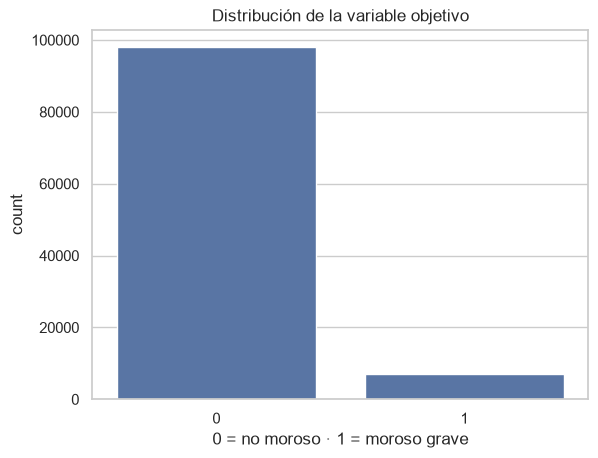

In [11]:
conteo = train[TARGET].value_counts().rename("clientes").to_frame()
conteo["porcentaje"] = (train[TARGET].value_counts(normalize=True) * 100).round(2)
display(conteo)

ax = sns.countplot(data=train, x=TARGET)
ax.set_title("Distribución de la variable objetivo")
ax.set_xlabel("0 = no moroso · 1 = moroso grave")
plt.show()

**Lectura:** la clase `1` es muy minoritaria (**datos desbalanceados**).
Consecuencias para el modelado:
- Accuracy no sirve: predecir siempre `0` ya daría ~93 %. Por eso la métrica es AUC-ROC.
- Conviene usar **validación cruzada estratificada** (mantiene la proporción en cada partición).
- Algunos modelos aceptan pesos de clase (`class_weight`).

## 5. Valores faltantes
¿Qué columnas tienen datos vacíos y cuántos?

In [12]:
faltantes = pd.DataFrame(
    {
        "n_faltantes": train[FEATS].isna().sum(),
        "% train": (train[FEATS].isna().mean() * 100).round(2),
        "% test": (test[FEATS].isna().mean() * 100).round(2),
    }
)
faltantes[faltantes["n_faltantes"] > 0]

,n_faltantes,% train,% test
MonthlyIncome,20828,19.84,19.78
NumberOfDependents,2771,2.64,2.56


In [13]:
# ¿Quien no reporta ingreso es más o menos moroso?
(
    train.groupby(train["MonthlyIncome"].isna())[TARGET]
    .agg(clientes="count", tasa_morosidad="mean")
    .rename_axis("ingreso_faltante")
    .round(4)
)

,clientes,tasa_morosidad
ingreso_faltante,,
False,84172,0.0695
True,20828,0.0561


**Lectura:** faltan datos en `MonthlyIncome` y en `NumberOfDependents`. El
patrón de faltantes es parecido en `train` y `test`.
Si la tasa de morosidad cambia cuando falta el ingreso, el hecho de que falte
**ya es información**: una opción es crear una columna indicadora
(`ingreso_faltante`) además de imputar (por ejemplo con la mediana).

## 6. Estadísticos descriptivos
Mínimo, máximo, media y percentiles de cada variable numérica.

In [14]:
train[FEATS].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max
RevolvingUtilizationOfUnsecuredLines,105000.0,6.41,273.64,0.0,0.0,0.03,0.15,0.56,1.09,50708.0
age,105000.0,52.29,14.78,0.0,24.0,41.00,52.00,63.00,87.00,103.0
NumberOfTime30-59DaysPastDueNotWorse,105000.0,0.43,4.29,0.0,0.0,0.00,0.00,0.00,4.00,98.0
DebtRatio,105000.0,358.33,2318.26,0.0,0.0,0.17,0.37,0.87,5011.01,329664.0
MonthlyIncome,84172.0,6645.49,15507.79,0.0,0.0,3400.00,5400.00,8208.00,25000.00,3008750.0
NumberOfOpenCreditLinesAndLoans,105000.0,8.44,5.13,0.0,0.0,5.00,8.00,11.00,24.00,58.0
NumberOfTimes90DaysLate,105000.0,0.27,4.26,0.0,0.0,0.00,0.00,0.00,3.00,98.0
NumberRealEstateLoansOrLines,105000.0,1.02,1.14,0.0,0.0,0.00,1.00,2.00,4.00,54.0
NumberOfTime60-89DaysPastDueNotWorse,105000.0,0.25,4.25,0.0,0.0,0.00,0.00,0.00,2.00,98.0
NumberOfDependents,102229.0,0.76,1.11,0.0,0.0,0.00,0.00,1.00,4.00,13.0


**Lectura:** la comparación de `50%` (mediana) con `mean` y con `max`
permite detectar dos problemas.
- Si `max` es enorme frente al `99%`, hay **valores atípicos** (*outliers*).
- Si `mean` está muy lejos de la mediana, la distribución tiene cola larga.

Destacan tres casos: `age` con mínimo 0,
`RevolvingUtilizationOfUnsecuredLines` muy por encima de 1 y las variables de
atraso con valores 96 o 98 (códigos especiales, no conteos reales).

## 7. Valores atípicos
Se revisan tres casos concretos.

In [15]:
print("Edad menor a 18:", (train["age"] < 18).sum())
print("Edad mayor a 90:", (train["age"] > 90).sum())
print("Utilización de líneas > 1:", (train["RevolvingUtilizationOfUnsecuredLines"] > 1).sum())
print("DebtRatio > 10:", (train["DebtRatio"] > 10).sum())

LATE = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
]
print("\nValores más altos en variables de atraso:")
for c in LATE:
    print(f"  {c}: {sorted(train[c].unique())[-4:]}")

Edad menor a 18: 1
Edad mayor a 90: 336
Utilización de líneas > 1: 2316
DebtRatio > 10: 20203

Valores más altos en variables de atraso:
  NumberOfTime30-59DaysPastDueNotWorse: [np.int64(12), np.int64(13), np.int64(96), np.int64(98)]
  NumberOfTime60-89DaysPastDueNotWorse: [np.int64(9), np.int64(11), np.int64(96), np.int64(98)]
  NumberOfTimes90DaysLate: [np.int64(14), np.int64(15), np.int64(96), np.int64(98)]


In [16]:
# Los valores 96 y 98 parecen códigos especiales: ¿cómo se comportan?
codigo = (train[LATE] >= 96).any(axis=1)
print("Filas con código 96/98:", codigo.sum())
print("Tasa de morosidad CON código   :", round(train.loc[codigo, TARGET].mean(), 4))
print("Tasa de morosidad SIN código   :", round(train.loc[~codigo, TARGET].mean(), 4))

Filas con código 96/98: 197
Tasa de morosidad CON código   : 0.5685
Tasa de morosidad SIN código   : 0.0659


**Lectura:** los 96/98 no son 96 atrasos reales: son marcas especiales y
además están asociadas a una tasa de morosidad muy distinta. Opciones:
tratarlos como categoría aparte, ponerlos en `NaN` y crear un indicador, o
recortar (*winsorizar*) el valor. Edades de 0 y razones de utilización o
deuda extremas se pueden recortar a un percentil alto (p. ej. 99).

## 8. Distribución de cada variable
Histogramas recortados al percentil 99 para que las colas extremas no
aplasten el gráfico.

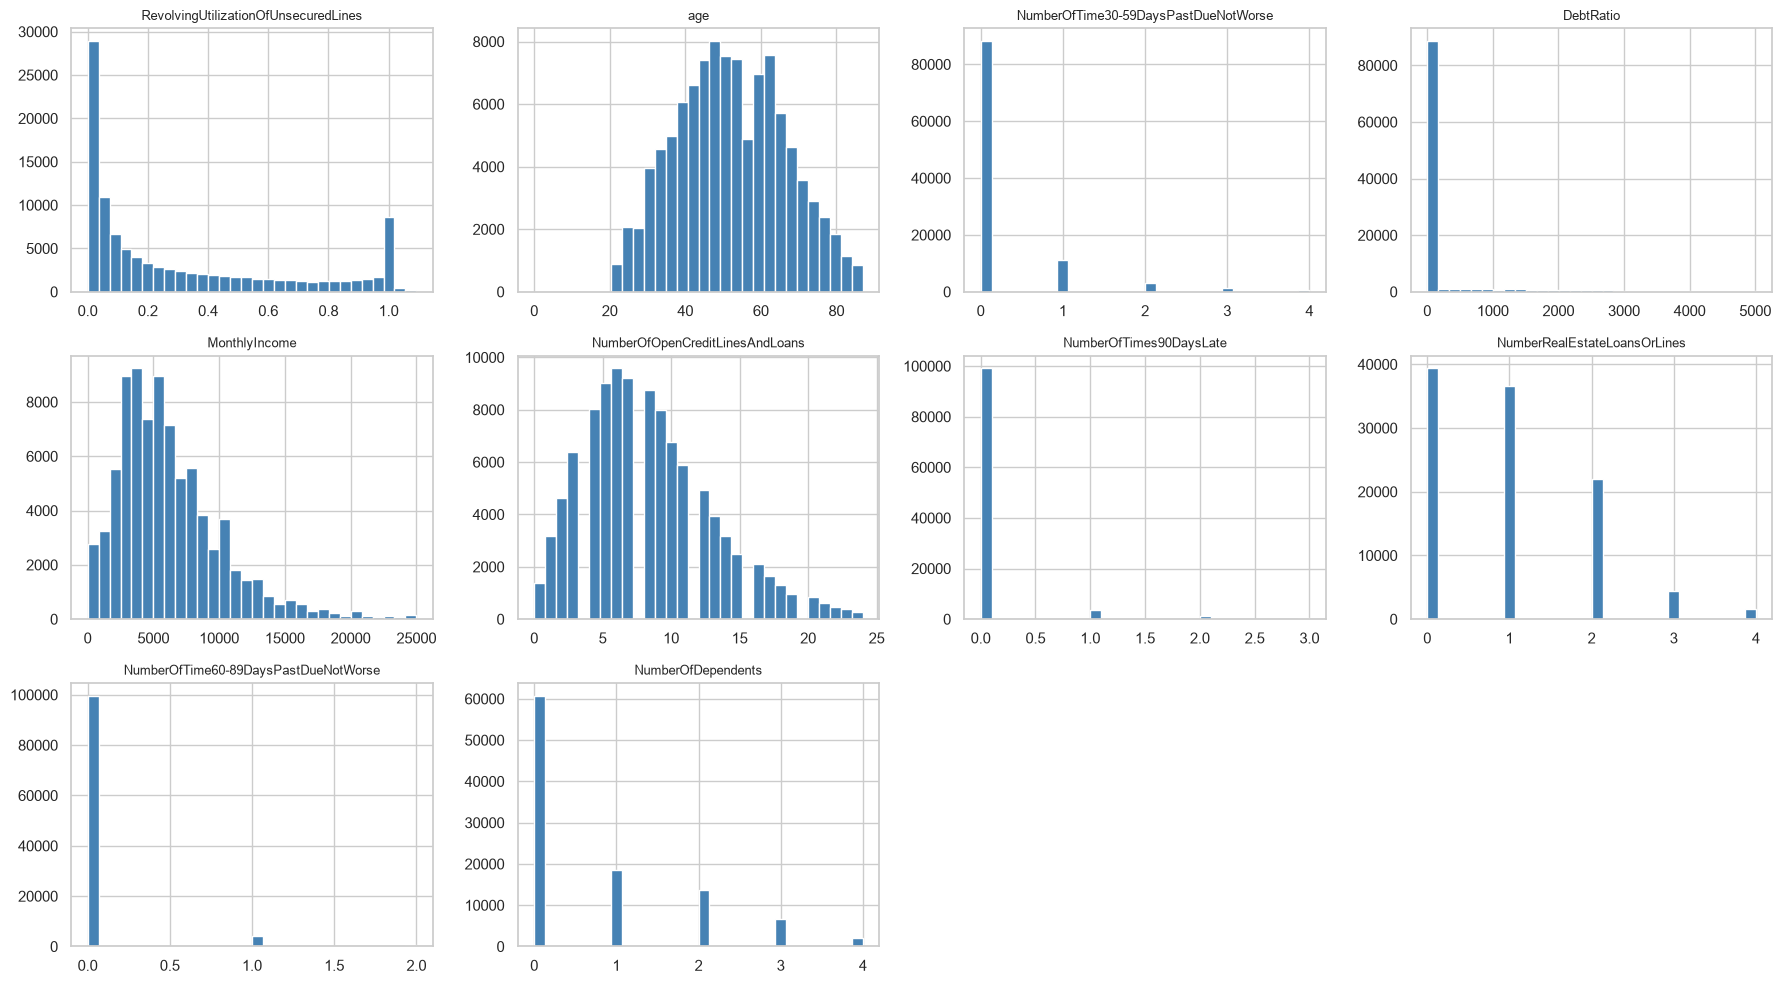

In [17]:
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, col in zip(axes.ravel(), FEATS):
    serie = train[col].dropna()
    serie = serie[serie <= serie.quantile(0.99)]
    ax.hist(serie, bins=30, color="steelblue")
    ax.set_title(col, fontsize=9)
for ax in axes.ravel()[len(FEATS):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Lectura:** la mayoría de las variables son muy asimétricas (muchos valores
pequeños y pocos grandes). Para modelos lineales ayuda aplicar `log1p` o
discretizar; los modelos de árboles no lo necesitan.

## 9. Relación de cada variable con el objetivo
¿Qué variables parecen separar a morosos de no morosos?

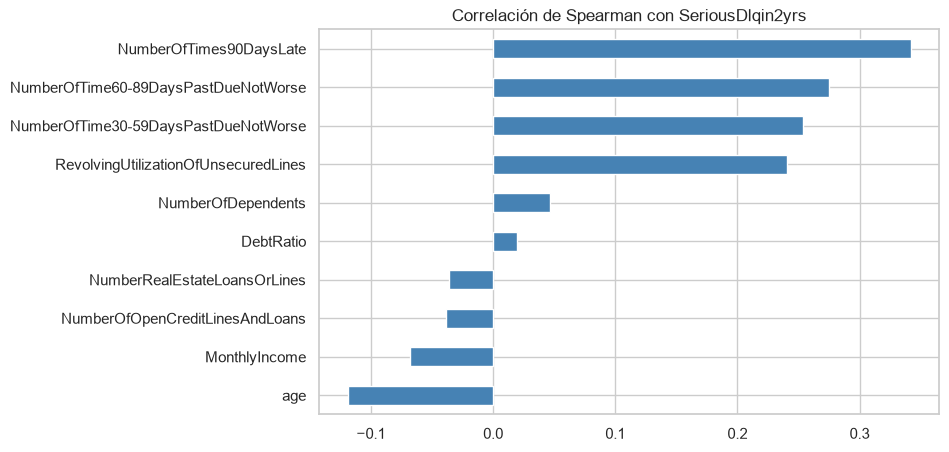

In [18]:
corr = train[FEATS + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET)
corr.sort_values().plot.barh(figsize=(8, 5), color="steelblue")
plt.title("Correlación de Spearman con SeriousDlqin2yrs")
plt.show()

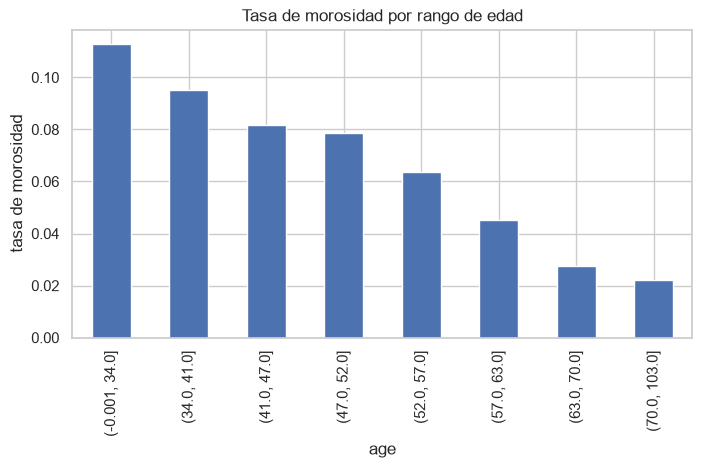

In [19]:
# Tasa de morosidad por rangos de edad (cuantiles)
rangos = pd.qcut(train["age"], 8)
train.groupby(rangos, observed=True)[TARGET].mean().plot(kind="bar", figsize=(8, 4))
plt.title("Tasa de morosidad por rango de edad")
plt.ylabel("tasa de morosidad")
plt.show()

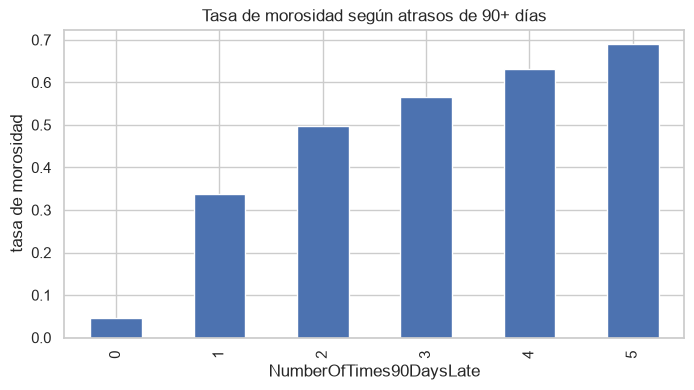

In [20]:
# Tasa de morosidad según número de atrasos de 90+ días (0 a 5)
t = train[train["NumberOfTimes90DaysLate"] <= 5]
t.groupby("NumberOfTimes90DaysLate")[TARGET].mean().plot(kind="bar", figsize=(8, 4))
plt.title("Tasa de morosidad según atrasos de 90+ días")
plt.ylabel("tasa de morosidad")
plt.show()

**Lectura:** las variables de atraso previo son las más relacionadas con la
morosidad futura, seguidas de la utilización de líneas de crédito
(`RevolvingUtilizationOfUnsecuredLines`). La edad tiene relación inversa (a
mayor edad, menor riesgo). Ideas de **ingeniería de variables** que salen de aquí:
- Suma total de atrasos (30-59 + 60-89 + 90+).
- Indicador de "tuvo algún atraso".
- Ingreso por dependiente (`MonthlyIncome / (NumberOfDependents + 1)`).
- Indicadores de faltante y de códigos 96/98.

## 10. Propuesta de preprocesamiento para la ingeniería de variables
Antes de la ingeniería de variables se definen, **con datos**, dos cosas
para cada variable:

1. Cómo tratar los valores faltantes y atípicos.
2. Si necesita escalado y de qué tipo.

**Dos tipos de transformación:**
- **Fijas (deterministas):** no aprenden nada de los datos, por ejemplo
  recortar a 2 o convertir 96/98 en `NaN`. Se pueden aplicar antes de la
  validación cruzada. Están en `clean_raw()` y `add_fixed_features()` de
  `src/features/engineering_jae.py`.
- **Aprendidas:** medianas, medias o desviaciones calculadas con los datos.
  Se ajustan **solo con el pliegue de entrenamiento** dentro de un
  `Pipeline`, para evitar fuga de datos.

### 10.1 Perfil de cada variable
- **Asimetría** (`skew`): 0 es simétrica; arriba de 1 tiene cola larga.
- **Asimetría con log:** cómo queda después de aplicar `log1p`.
- **% ceros:** si es muy alto, la variable se comporta casi como binaria.

In [21]:
perfil = pd.DataFrame(
    {
        "mín": train[FEATS].min(),
        "p99": train[FEATS].quantile(0.99),
        "máx": train[FEATS].max(),
        "asimetría": train[FEATS].skew(),
        "asimetría con log1p": np.log1p(train[FEATS].clip(lower=0)).skew(),
        "% ceros": (train[FEATS] == 0).mean() * 100,
        "% faltantes": train[FEATS].isna().mean() * 100,
    }
).round(2)
perfil.sort_values("asimetría", ascending=False)

,mín,p99,máx,asimetría,asimetría con log1p,% ceros,% faltantes
MonthlyIncome,0.0,25000.00,3008750.0,123.09,-4.38,1.09,19.84
RevolvingUtilizationOfUnsecuredLines,0.0,1.09,50708.0,98.41,11.74,7.29,0.00
DebtRatio,0.0,5011.01,329664.0,91.80,1.75,2.79,0.00
NumberOfTime60-89DaysPastDueNotWorse,0.0,2.00,98.0,22.81,10.64,94.95,0.00
NumberOfTimes90DaysLate,0.0,3.00,98.0,22.58,8.83,94.44,0.00
NumberOfTime30-59DaysPastDueNotWorse,0.0,4.00,98.0,22.12,4.32,84.05,0.00
NumberRealEstateLoansOrLines,0.0,4.00,54.0,3.99,0.25,37.51,0.00
NumberOfDependents,0.0,4.00,13.0,1.55,0.84,57.90,2.64
NumberOfOpenCreditLinesAndLoans,0.0,24.00,58.0,1.19,-0.75,1.30,0.00
age,0.0,87.00,103.0,0.19,-0.46,0.00,0.00


**Lectura:**
- `MonthlyIncome`, `RevolvingUtilizationOfUnsecuredLines` y `DebtRatio`
  tienen asimetría enorme (90 a 120): el máximo está a miles de veces del
  p99. Primero hay que **recortar** y después **transformar**.
- Las tres variables de atraso tienen entre 84 % y 95 % de ceros: se
  comportan casi como "tuvo o no tuvo atraso".
- `age` es casi simétrica: solo necesita estandarizarse.

### 10.2 Detalle del ingreso mensual: ¿qué tan dispersos están los datos?

In [22]:
ingreso = train["MonthlyIncome"].dropna()
q1, q3 = ingreso.quantile([0.25, 0.75])
iqr = q3 - q1
limite_atipico = q3 + 1.5 * iqr

dispersion = pd.Series(
    {
        "registros con ingreso": len(ingreso),
        "media": ingreso.mean(),
        "mediana": ingreso.median(),
        "desviación estándar": ingreso.std(),
        "coeficiente de variación (desv / media)": ingreso.std() / ingreso.mean(),
        "p5": ingreso.quantile(0.05),
        "p25 (Q1)": q1,
        "p75 (Q3)": q3,
        "p95": ingreso.quantile(0.95),
        "p99": ingreso.quantile(0.99),
        "p99.9": ingreso.quantile(0.999),
        "máximo": ingreso.max(),
        "rango intercuartil (IQR)": iqr,
        "límite de atípico (Q3 + 1.5·IQR)": limite_atipico,
        "% arriba del límite de atípico": (ingreso > limite_atipico).mean() * 100,
        "ingreso = 0": (ingreso == 0).sum(),
        "ingreso entre 1 y 100": ingreso.between(1, 100).sum(),
    },
    name="valor",
)
dispersion.round(2).to_frame()

,valor
registros con ingreso,84172.00
media,6645.49
mediana,5400.00
desviación estándar,15507.79
coeficiente de variación (desv / media),2.33
p5,1287.10
p25 (Q1),3400.00
p75 (Q3),8208.00
p95,14550.00
p99,25000.00


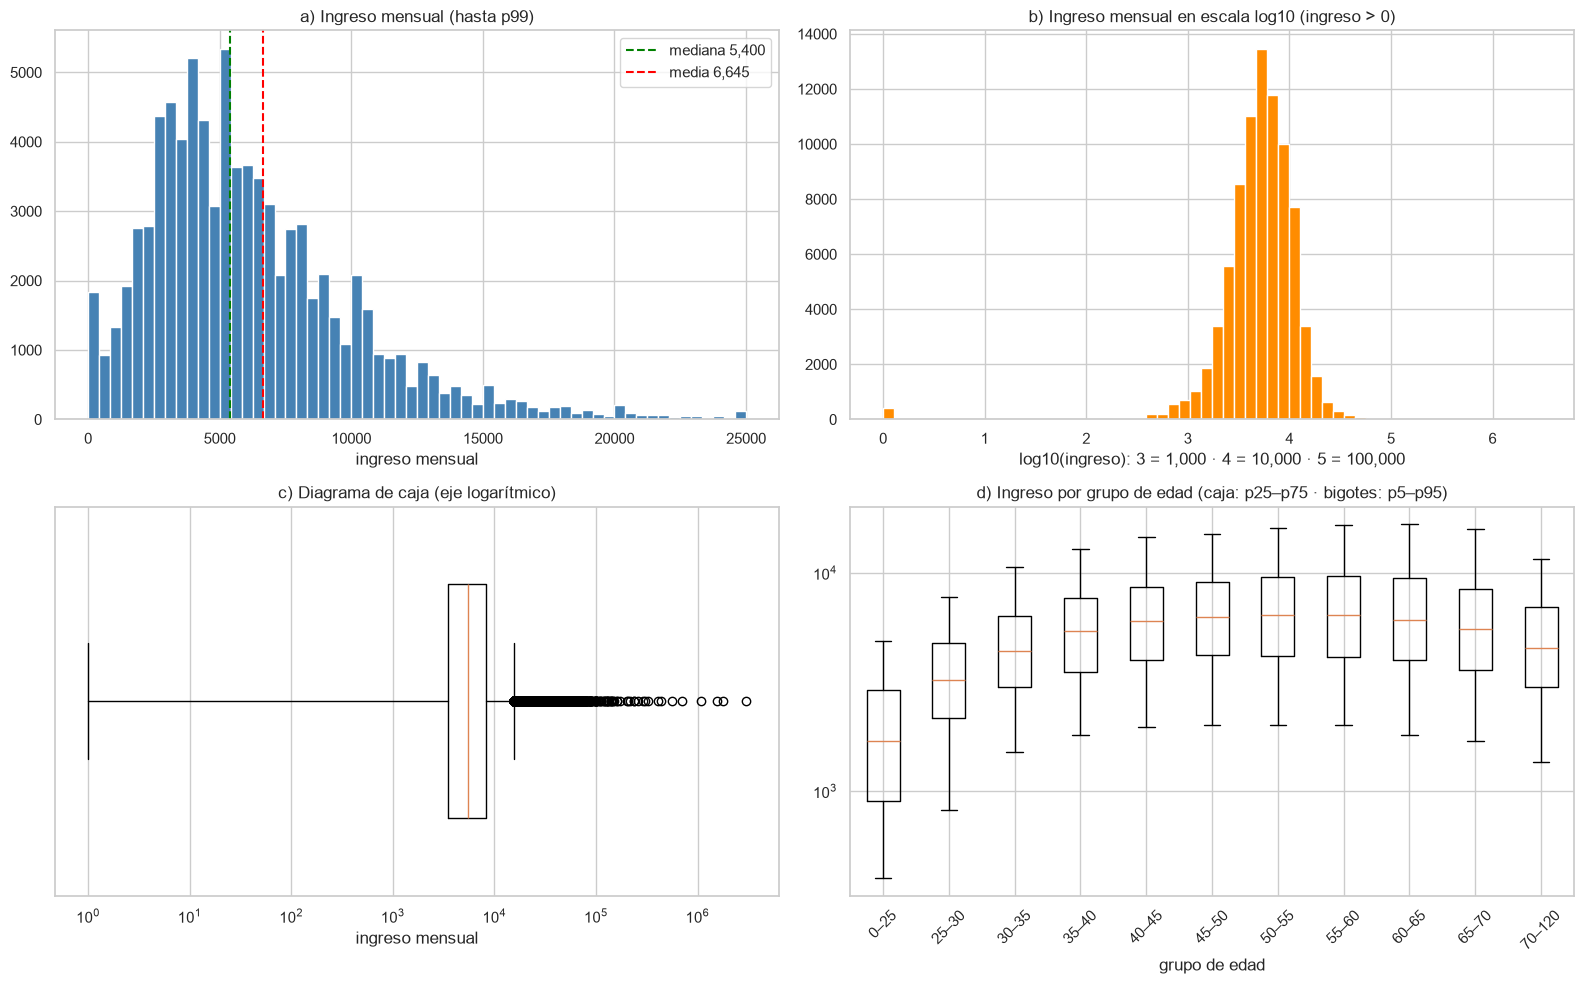

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
p99 = ingreso.quantile(0.99)

# a) Escala original, sin el 1 % más alto
ax = axes[0, 0]
ax.hist(ingreso[ingreso <= p99], bins=60, color="steelblue")
ax.axvline(ingreso.median(), color="green", ls="--", label=f"mediana {ingreso.median():,.0f}")
ax.axvline(ingreso.mean(), color="red", ls="--", label=f"media {ingreso.mean():,.0f}")
ax.set_title("a) Ingreso mensual (hasta p99)")
ax.set_xlabel("ingreso mensual")
ax.legend()

# b) Escala logarítmica: se ve la distribución completa
ax = axes[0, 1]
ax.hist(np.log10(ingreso[ingreso > 0]), bins=60, color="darkorange")
ax.set_title("b) Ingreso mensual en escala log10 (ingreso > 0)")
ax.set_xlabel("log10(ingreso): 3 = 1,000 · 4 = 10,000 · 5 = 100,000")

# c) Caja: dónde se concentra el 50 % central y cuántos atípicos hay
ax = axes[1, 0]
ax.boxplot([ingreso[ingreso > 0].to_numpy()], orientation="horizontal", widths=0.6)
ax.set_xscale("log")
ax.set_title("c) Diagrama de caja (eje logarítmico)")
ax.set_xlabel("ingreso mensual")
ax.set_yticks([])

# d) Dispersión por grupo de edad
ax = axes[1, 1]
CORTES_EDAD = [0, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 120]
con_edad = train.loc[train["MonthlyIncome"] > 0, ["age", "MonthlyIncome"]].copy()
con_edad["grupo_edad"] = pd.cut(con_edad["age"], CORTES_EDAD)
orden_grupos = con_edad["grupo_edad"].cat.categories
ax.boxplot(
    [con_edad.loc[con_edad["grupo_edad"] == g, "MonthlyIncome"].to_numpy()
     for g in orden_grupos],
    tick_labels=[f"{int(g.left)}–{int(g.right)}" for g in orden_grupos],
    whis=(5, 95),
    showfliers=False,
)
ax.set_yscale("log")
ax.set_title("d) Ingreso por grupo de edad (caja: p25–p75 · bigotes: p5–p95)")
ax.set_xlabel("grupo de edad")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Lectura:** el ingreso está **muy disperso**.
- La desviación estándar (15,508) es más del doble de la media (6,646):
  coeficiente de variación de 2.3. Arriba de 1 ya se considera alta.
- La media está por encima de la mediana (5,400) porque unos pocos ingresos
  enormes la jalan: el máximo es 3 millones, 120 veces el p99 (25,000).
- El 50 % central está entre 3,400 y 8,208 (IQR de 4,808), y el 4.1 % queda
  arriba del límite de atípico (15,420).
- En el extremo bajo hay 1,143 ingresos en 0 y 468 entre 1 y 100, que no
  son ingresos mensuales creíbles.
- En escala logarítmica (b) la distribución se ve casi normal: por eso se
  usa `log1p` antes de escalar.
- La gráfica (d) confirma que el ingreso cambia con la edad, pero dentro de
  cada grupo la dispersión sigue siendo amplia.

### 10.3 Valores faltantes
Faltan datos en `MonthlyIncome` (19.8 %) y `NumberOfDependents` (2.6 %).

**a) ¿Los faltantes de las dos variables están relacionados?**

In [24]:
falta_ingreso = train["MonthlyIncome"].isna()
falta_dependientes = train["NumberOfDependents"].isna()
pd.crosstab(
    falta_ingreso.rename("falta ingreso"),
    falta_dependientes.rename("faltan dependientes"),
    margins=True,
    margins_name="total",
)

faltan dependientes,False,True,total
falta ingreso,,,
False,84172,0,84172
True,18057,2771,20828
total,102229,2771,105000


**Lectura:** todos los clientes sin `NumberOfDependents` tampoco tienen
ingreso. Es el mismo problema de captura, y por eso los indicadores de
faltante son importantes.

**b) Cuando falta el ingreso, ¿está informado el `DebtRatio`?**

In [25]:
debt_sin_ingreso = train.loc[falta_ingreso, "DebtRatio"]
pd.Series(
    {
        "registros sin ingreso": len(debt_sin_ingreso),
        "con DebtRatio informado": debt_sin_ingreso.notna().sum(),
        "con DebtRatio = 0": (debt_sin_ingreso == 0).sum(),
        "% de valores enteros": (debt_sin_ingreso == debt_sin_ingreso.round()).mean() * 100,
    },
    name="valor",
).round(1).to_frame()

,valor
registros sin ingreso,20828.0
con DebtRatio informado,20828.0
con DebtRatio = 0,1162.0
% de valores enteros,100.0


In [26]:
pd.DataFrame(
    {
        "DebtRatio mediano": train.groupby(falta_ingreso)["DebtRatio"].median(),
        "% con DebtRatio > 1": train["DebtRatio"].gt(1).groupby(falta_ingreso).mean()
        * 100,
    }
).rename_axis("falta ingreso").round(2)

,DebtRatio mediano,% con DebtRatio > 1
falta ingreso,,
False,0.3,6.07
True,1158.0,93.79


**Lectura:** **sí**: los 20,828 registros sin ingreso tienen `DebtRatio`
informado (1,162 en cero). Pero ahí no es una razón:
- Con ingreso, el `DebtRatio` mediano es 0.30. Sin ingreso es **1,158** y
  el 94 % supera 1.
- El 100 % son números enteros, como un monto en dinero.

Todo indica que, sin ingreso, el sistema guardó el **monto mensual de la
deuda** (la razón dividida entre 1). Si la hipótesis es correcta, su
distribución debe parecerse a la del monto de deuda de los clientes que sí
tienen ingreso (`DebtRatio × MonthlyIncome`):

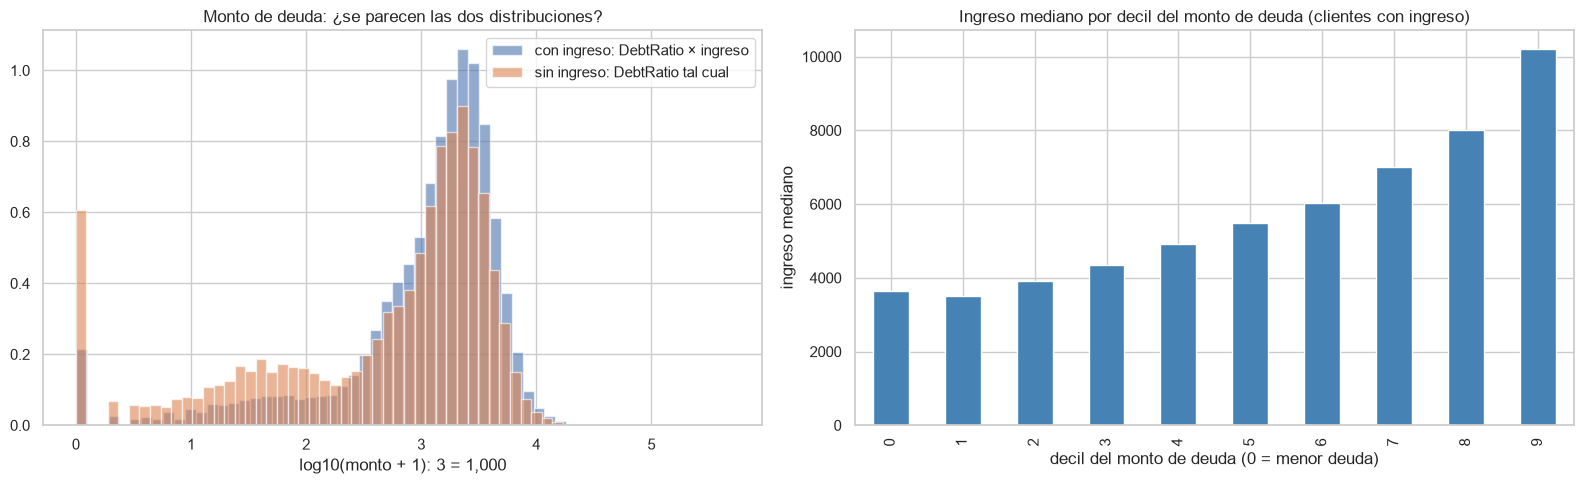

Correlación de Spearman entre monto de deuda e ingreso: 0.498


In [27]:
con_ingreso = train[train["MonthlyIncome"] > 0].copy()
con_ingreso["monto_deuda"] = con_ingreso["DebtRatio"] * con_ingreso["MonthlyIncome"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ax = axes[0]
ax.hist(np.log10(con_ingreso["monto_deuda"] + 1), bins=60, alpha=0.6, density=True,
        label="con ingreso: DebtRatio × ingreso")
ax.hist(np.log10(debt_sin_ingreso + 1), bins=60, alpha=0.6, density=True,
        label="sin ingreso: DebtRatio tal cual")
ax.set_title("Monto de deuda: ¿se parecen las dos distribuciones?")
ax.set_xlabel("log10(monto + 1): 3 = 1,000")
ax.legend()

# ¿El monto de deuda dice algo del ingreso?
deciles_deuda = pd.qcut(con_ingreso["monto_deuda"].rank(method="first"), 10, labels=False)
ax = axes[1]
con_ingreso.groupby(deciles_deuda)["MonthlyIncome"].median().plot(
    kind="bar", color="steelblue", ax=ax
)
ax.set_title("Ingreso mediano por decil del monto de deuda (clientes con ingreso)")
ax.set_xlabel("decil del monto de deuda (0 = menor deuda)")
ax.set_ylabel("ingreso mediano")
plt.tight_layout()
plt.show()

print(
    "Correlación de Spearman entre monto de deuda e ingreso:",
    round(con_ingreso[["monto_deuda", "MonthlyIncome"]].corr("spearman").iloc[0, 1], 3),
)

**Lectura:**
- La parte principal de las dos distribuciones coincide (izquierda): ambas
  se concentran alrededor de 1,000–3,000, lo que respalda la hipótesis de que,
  sin ingreso, `DebtRatio` es el monto de la deuda. La diferencia es que los
  clientes sin ingreso tienen más montos bajos (10 a 100) y más ceros: son
  clientes con poca o ninguna deuda.
- **Sí se puede inferir parcialmente el ingreso a partir de este campo:**
  el ingreso mediano sube de forma ordenada con el monto de deuda
  (derecha), con una correlación de Spearman de 0.50, la más alta de
  cualquier variable con el ingreso. Quien paga más deuda suele ganar más.
- No es una fórmula exacta: la razón real de esos clientes no se conoce,
  así que solo se puede estimar un ingreso típico para su nivel de deuda.

**c) ¿El ingreso cambia con la edad y con los créditos hipotecarios?**

,ingreso_mediano,pct_sin_ingreso,dependientes_medianos,dependientes_promedio
age,,,,
"(0, 25]",1600.0,20.41,0.0,0.14
"(25, 30]",3200.0,14.30,0.0,0.41
"(30, 35]",4350.0,12.82,0.0,0.78
"(35, 40]",5316.0,14.18,1.0,1.18
"(40, 45]",5978.0,14.74,1.0,1.34
"(45, 50]",6250.0,16.34,1.0,1.24
"(50, 55]",6300.0,18.24,0.0,0.94
"(55, 60]",6333.0,21.12,0.0,0.61
"(60, 65]",6000.0,24.80,0.0,0.40


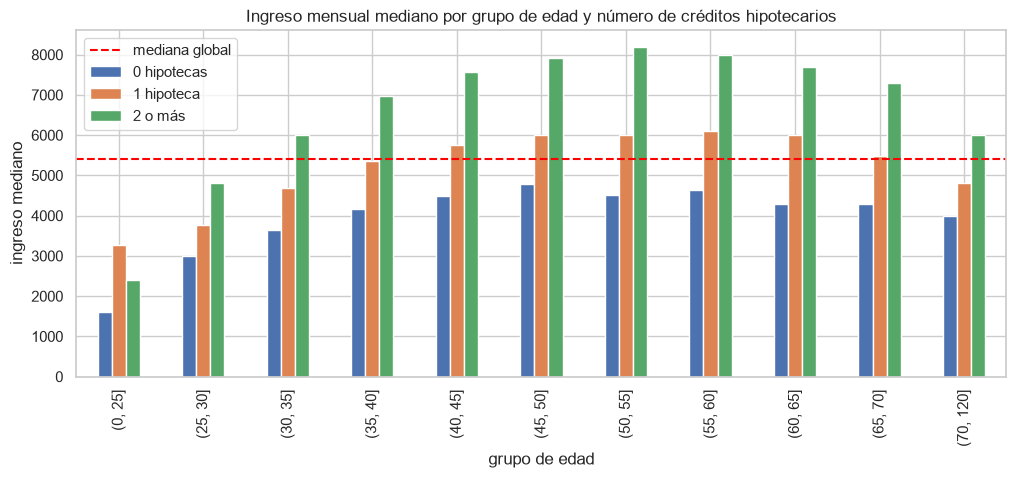

NumberRealEstateLoansOrLines,0 hipotecas,1 hipoteca,2 o más
age,,,
"(0, 25]",1600.0,3267.0,2400.0
"(25, 30]",3000.0,3764.0,4800.0
"(30, 35]",3632.0,4676.0,6000.0
"(35, 40]",4166.0,5355.0,6982.0
"(40, 45]",4500.0,5750.0,7570.0
"(45, 50]",4789.0,6000.0,7916.0
"(50, 55]",4520.0,6000.0,8200.0
"(55, 60]",4634.0,6105.0,8000.0
"(60, 65]",4300.0,6000.0,7702.0


In [28]:
grupo_edad = pd.cut(train["age"], CORTES_EDAD)
ingreso_por_edad = train.groupby(grupo_edad, observed=True).agg(
    ingreso_mediano=("MonthlyIncome", "median"),
    pct_sin_ingreso=("MonthlyIncome", lambda s: s.isna().mean() * 100),
    dependientes_medianos=("NumberOfDependents", "median"),
    dependientes_promedio=("NumberOfDependents", "mean"),
)
display(ingreso_por_edad.round(2))

hipotecas = train["NumberRealEstateLoansOrLines"].clip(upper=2).map(
    {0: "0 hipotecas", 1: "1 hipoteca", 2: "2 o más"}
)
tabla_edad_hipotecas = train.pivot_table(
    index=grupo_edad, columns=hipotecas, values="MonthlyIncome",
    aggfunc="median", observed=True,
)
ax = tabla_edad_hipotecas.plot(kind="bar", figsize=(12, 4.5))
ax.axhline(train["MonthlyIncome"].median(), color="red", ls="--", label="mediana global")
ax.set_title("Ingreso mensual mediano por grupo de edad y número de créditos hipotecarios")
ax.set_xlabel("grupo de edad")
ax.set_ylabel("ingreso mediano")
ax.legend()
plt.show()
tabla_edad_hipotecas.round(0)

**Lectura:** el ingreso mediano va de 1,600 (≤ 25 años) a 6,333 (55–60
años). Y **dentro de cada grupo de edad, tener créditos hipotecarios marca
una diferencia grande**: quien tiene 2 o más hipotecas gana bastante más que
quien no tiene ninguna. Con una sola mediana global (5,400) se le asignaría
el mismo ingreso a todos. Además, los mayores de 60 son los que más ingreso
dejan en blanco (25–31 %).

**d) ¿Qué estrategia imputa mejor el ingreso?**

**Protocolo:** de los clientes que **sí** tienen ingreso (> 0) se reserva
el 30 %, se oculta su ingreso y se mide qué tan cerca queda cada estrategia
del valor real. El error se mide en escala logarítmica porque el ingreso es
muy asimétrico; menor error es mejor. Todas las medianas y los cortes de
cuantiles se calculan solo con el 70 % de ajuste.

**Estrategias comparadas:**
- **A:** edad + número de créditos hipotecarios.
- **B:** edad + decil del monto mensual de deuda.
- Alternativas que **no usan ni las hipotecas ni el monto de deuda**: edad
  combinada con la utilización de la línea de crédito, con los dependientes
  y con el número de líneas de crédito abiertas.
- **C:** edad + líneas de crédito abiertas + dependientes.

In [29]:
from sklearn.model_selection import train_test_split

base = con_ingreso.copy()
# Número de grupo de edad; la edad 0 (fuera de los cortes) va al grupo más joven
base["grupo_edad"] = (
    pd.cut(base["age"], CORTES_EDAD, labels=False).fillna(0).astype(int).astype(str)
)
base["hipotecas"] = base["NumberRealEstateLoansOrLines"].clip(upper=2).astype(str)
ajuste, prueba = train_test_split(base, test_size=0.3, random_state=42)

# Deciles del monto de deuda con cortes aprendidos solo en el ajuste
cortes_deuda = np.quantile(ajuste["monto_deuda"], np.linspace(0, 1, 11))
cortes_deuda[0], cortes_deuda[-1] = -np.inf, np.inf
for df in (ajuste, prueba):
    df["decil_deuda"] = pd.cut(df["monto_deuda"], cortes_deuda, labels=False).astype(str)
    df["edad_hipotecas"] = df["grupo_edad"] + "_" + df["hipotecas"]
    df["edad_deuda"] = df["grupo_edad"] + "_" + df["decil_deuda"]


def cortes_cuantiles(valores: pd.Series, n_rangos: int) -> np.ndarray:
    """Calcula cortes por cuantiles interiores, con extremos en ±infinito.

    Args:
        valores: Valores observados en los datos de ajuste (sin faltantes).
        n_rangos: Número máximo de rangos.

    Returns:
        Cortes ordenados, de ``-inf`` a ``inf``, sin repetidos.
    """
    interiores = np.unique(np.quantile(valores, np.linspace(0, 1, n_rangos + 1)[1:-1]))
    return np.concatenate([[-np.inf], interiores, [np.inf]])


def agregar_grupos_perfil(
    df: pd.DataFrame, cortes_lineas: np.ndarray, cortes_util: np.ndarray
) -> None:
    """Agrega los grupos que no dependen de hipotecas ni del monto de deuda.

    Args:
        df: Datos a los que se agregan las columnas de grupo (se modifica).
        cortes_lineas: Cortes del número de líneas de crédito abiertas.
        cortes_util: Cortes de la utilización de las líneas revolventes.
    """
    lineas = pd.cut(
        df["NumberOfOpenCreditLinesAndLoans"], cortes_lineas, labels=False
    ).astype(str)
    utilizacion = pd.cut(
        df["RevolvingUtilizationOfUnsecuredLines"], cortes_util, labels=False
    ).astype(str)
    # 0, 1 o 2+ dependientes; el faltante queda como grupo aparte ("nd")
    dependientes = (
        df["NumberOfDependents"].clip(upper=2).map("{:.0f}".format, na_action="ignore")
    ).fillna("nd")
    df["edad_utilizacion"] = df["grupo_edad"] + "_" + utilizacion
    df["edad_dependientes"] = df["grupo_edad"] + "_" + dependientes
    df["edad_lineas"] = df["grupo_edad"] + "_" + lineas
    df["edad_lineas_dependientes"] = df["edad_lineas"] + "_" + dependientes


# Quintiles con cortes aprendidos solo en el ajuste
cortes_lineas = cortes_cuantiles(ajuste["NumberOfOpenCreditLinesAndLoans"], 5)
cortes_util = cortes_cuantiles(ajuste["RevolvingUtilizationOfUnsecuredLines"], 5)
for df in (ajuste, prueba):
    agregar_grupos_perfil(df, cortes_lineas, cortes_util)

mediana_global = ajuste["MonthlyIncome"].median()
log_real = np.log1p(prueba["MonthlyIncome"])
MIN_GRUPO = 30  # clientes mínimos para confiar en la mediana de un grupo
# Estrategia C: del grupo más fino al más general
NIVELES_C = ["edad_lineas_dependientes", "edad_lineas", "grupo_edad"]


def imputar_por_niveles(
    conocidos_df: pd.DataFrame,
    destino_df: pd.DataFrame,
    niveles: list[str],
    minimo: int = MIN_GRUPO,
) -> pd.Series:
    """Imputa el ingreso con la mediana del grupo más fino que tenga datos.

    Recorre ``niveles`` del más fino al más general. Un grupo solo se usa si
    tiene al menos ``minimo`` clientes con ingreso; si no, se pasa al nivel
    siguiente y, al final, a la mediana global.

    Args:
        conocidos_df: Clientes con ingreso, de donde se aprenden las medianas.
        destino_df: Clientes a los que se les imputa el ingreso.
        niveles: Columnas de grupo, de la más fina a la más general.
        minimo: Número mínimo de clientes para usar la mediana de un grupo.

    Returns:
        Ingreso imputado para cada fila de ``destino_df``.
    """
    imputado = pd.Series(np.nan, index=destino_df.index)
    for nivel in niveles:
        resumen = conocidos_df.groupby(nivel)["MonthlyIncome"].agg(["median", "size"])
        medianas = resumen.loc[resumen["size"] >= minimo, "median"]
        imputado = imputado.fillna(destino_df[nivel].map(medianas))
    return imputado.fillna(conocidos_df["MonthlyIncome"].median())


def error_imputacion(grupo: str | list[str] | None) -> float:
    """Error absoluto medio en log1p al imputar con la mediana de un grupo.

    Args:
        grupo: Columna que define los grupos; una lista indica niveles con
            respaldo (ver ``imputar_por_niveles``) y ``None`` usa la mediana
            global.

    Returns:
        Error absoluto medio entre el ingreso real e imputado en escala log1p.
    """
    if grupo is None:
        imputado = pd.Series(mediana_global, index=prueba.index)
    elif isinstance(grupo, list):
        imputado = imputar_por_niveles(ajuste, prueba, grupo)
    else:
        medianas = ajuste.groupby(grupo)["MonthlyIncome"].median()
        imputado = prueba[grupo].map(medianas).fillna(mediana_global)
    return float((log_real - np.log1p(imputado)).abs().mean())


def numero_de_grupos(grupo: str | list[str] | None) -> int:
    """Cuenta los grupos que usa una estrategia de imputación.

    Args:
        grupo: Columna que define los grupos; una lista indica niveles con
            respaldo (se cuenta el más fino) y ``None`` es la mediana global.

    Returns:
        Número de grupos en los datos de ajuste.
    """
    if grupo is None:
        return 1
    return int(ajuste[grupo[0] if isinstance(grupo, list) else grupo].nunique())


estrategias = {
    "mediana global": None,
    "mediana por grupo de edad": "grupo_edad",
    "edad + utilización de la línea de crédito (quintil)": "edad_utilizacion",
    "edad + dependientes (0, 1, 2+)": "edad_dependientes",
    "edad + n.º de líneas de crédito abiertas (quintil)": "edad_lineas",
    "⭐ C: edad + líneas de crédito + dependientes": NIVELES_C,
    "A (descartada): edad + n.º de créditos hipotecarios": "edad_hipotecas",
    "mediana por decil del monto de deuda": "decil_deuda",
    "🔷 B (alternativa): edad + decil del monto de deuda": "edad_deuda",
}
comparacion = pd.DataFrame(
    {
        "grupos": [numero_de_grupos(g) for g in estrategias.values()],
        "error (MAE en log)": [error_imputacion(g) for g in estrategias.values()],
    },
    index=list(estrategias),
)
comparacion["mejora vs global (%)"] = (
    1 - comparacion["error (MAE en log)"] / comparacion["error (MAE en log)"].iloc[0]
) * 100
comparacion.round(3)

,grupos,error (MAE en log),mejora vs global (%)
mediana global,1,0.577,0.000
mediana por grupo de edad,11,0.543,5.915
edad + utilización de la línea de crédito (quintil),55,0.538,6.690
"edad + dependientes (0, 1, 2+)",33,0.535,7.264
edad + n.º de líneas de crédito abiertas (quintil),55,0.527,8.572
⭐ C: edad + líneas de crédito + dependientes,162,0.521,9.656
A (descartada): edad + n.º de créditos hipotecarios,33,0.515,10.611
mediana por decil del monto de deuda,10,0.498,13.678
🔷 B (alternativa): edad + decil del monto de deuda,109,0.484,16.125


**¿Por qué funcionan las líneas de crédito y los dependientes?** Dentro de
cada grupo de edad, el ingreso mediano debería cambiar con ellos.

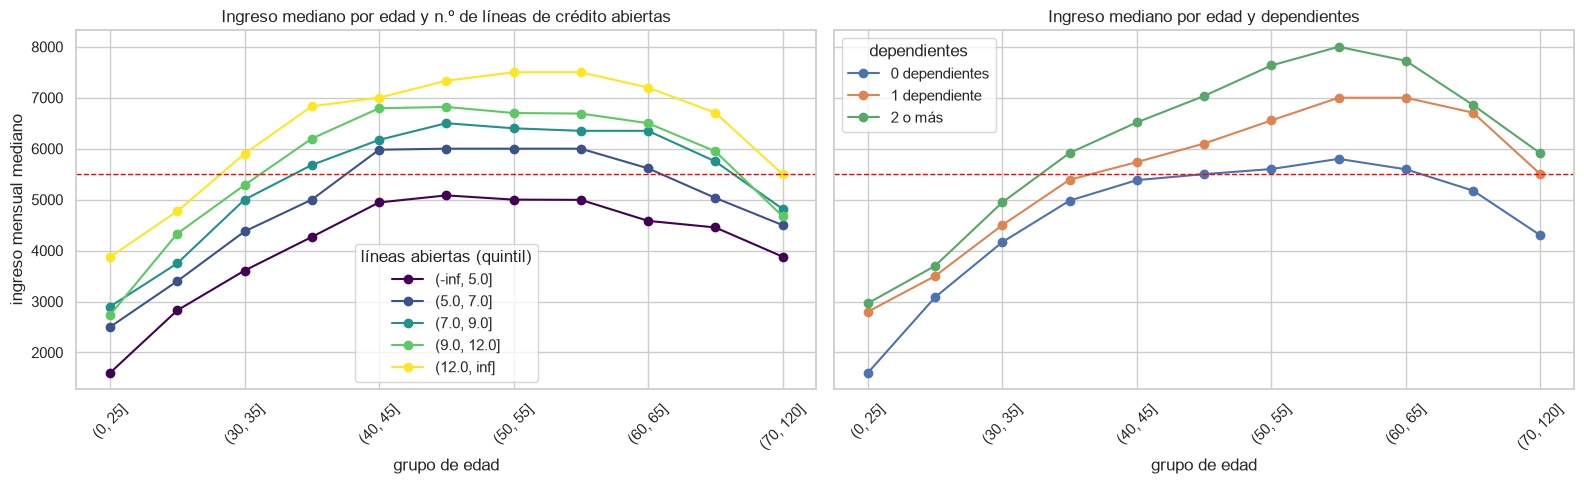

NumberOfOpenCreditLinesAndLoans,"(-inf, 5.0]","(5.0, 7.0]","(7.0, 9.0]","(9.0, 12.0]","(12.0, inf]"
age,,,,,
"(0, 25]",1600.0,2500.0,2900.0,2736.0,3875.0
"(25, 30]",2827.0,3400.0,3750.0,4333.0,4770.0
"(30, 35]",3607.0,4375.0,5000.0,5286.0,5900.0
"(35, 40]",4268.0,5000.0,5680.0,6198.0,6833.0
"(40, 45]",4944.0,5980.0,6172.0,6793.0,7000.0
"(45, 50]",5083.0,6000.0,6500.0,6820.0,7333.0
"(50, 55]",5000.0,6000.0,6400.0,6700.0,7500.0
"(55, 60]",4996.0,6000.0,6350.0,6689.0,7500.0
"(60, 65]",4583.0,5614.0,6350.0,6500.0,7200.0


NumberOfDependents,0 dependientes,1 dependiente,2 o más
age,,,
"(0, 25]",1600.0,2800.0,2966.0
"(25, 30]",3084.0,3500.0,3700.0
"(30, 35]",4166.0,4500.0,4947.0
"(35, 40]",4980.0,5390.0,5916.0
"(40, 45]",5382.0,5737.0,6516.0
"(45, 50]",5500.0,6100.0,7034.0
"(50, 55]",5600.0,6554.0,7633.0
"(55, 60]",5800.0,7000.0,8000.0
"(60, 65]",5595.0,7000.0,7725.0


In [30]:
ETIQUETAS_DEP = {"0": "0 dependientes", "1": "1 dependiente", "2": "2 o más"}
base_perfil = base.copy()
agregar_grupos_perfil(base_perfil, cortes_lineas, cortes_util)
edad_intervalo = pd.cut(base_perfil["age"], CORTES_EDAD)
quintil_lineas = pd.cut(
    base_perfil["NumberOfOpenCreditLinesAndLoans"], cortes_lineas
).astype(str)
dependientes_grupo = base_perfil["NumberOfDependents"].clip(upper=2).map(
    lambda v: ETIQUETAS_DEP[f"{v:.0f}"], na_action="ignore"
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
tabla_edad_lineas = base_perfil.pivot_table(
    index=edad_intervalo, columns=quintil_lineas, values="MonthlyIncome",
    aggfunc="median", observed=True,
)
orden_lineas = sorted(tabla_edad_lineas.columns, key=lambda c: float(c.split(",")[1][:-1]))
tabla_edad_lineas[orden_lineas].plot(marker="o", ax=axes[0], colormap="viridis")
axes[0].set_title("Ingreso mediano por edad y n.º de líneas de crédito abiertas")
axes[0].legend(title="líneas abiertas (quintil)")

tabla_edad_dep = base_perfil.pivot_table(
    index=edad_intervalo, columns=dependientes_grupo, values="MonthlyIncome",
    aggfunc="median", observed=True,
)
tabla_edad_dep[list(ETIQUETAS_DEP.values())].plot(marker="o", ax=axes[1])
axes[1].set_title("Ingreso mediano por edad y dependientes")
axes[1].legend(title="dependientes")
for ax in axes:
    ax.axhline(mediana_global, color="red", ls="--", lw=1)
    ax.set_xlabel("grupo de edad")
    ax.set_ylabel("ingreso mensual mediano")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
display(tabla_edad_lineas[orden_lineas].round(0))
display(tabla_edad_dep[list(ETIQUETAS_DEP.values())].round(0))

**Lectura de la comparación:**
- **Edad + utilización de la línea de crédito** casi no ayuda: 6.7 % de
  mejora contra 5.9 % de la edad sola. La utilización dice mucho de la
  morosidad, pero muy poco del ingreso (Spearman −0.09).
- **Edad + dependientes** ayuda un poco más (7.3 %). Tiene un límite: el
  13.4 % de los clientes sin ingreso tampoco tiene dependientes informados,
  así que por sí sola no alcanza para todos.
- **Edad + número de líneas de crédito abiertas** es la mejor pareja
  (8.6 %). Es la variable más relacionada con el ingreso después de las
  hipotecas y la deuda (Spearman 0.31), y **siempre está informada**.
- **⭐ C: edad + líneas de crédito + dependientes** junta las dos señales y
  llega a 9.7 %, casi lo mismo que A (10.6 %).
- B es la más precisa (16.1 %), pero es la única que depende del
  monto de deuda.

**Lectura de las gráficas:** dentro de cada grupo de edad las curvas quedan
ordenadas y casi no se cruzan.
- *Líneas de crédito:* entre 45 y 50 años, quien tiene 5 líneas o menos gana
  5,083 y quien tiene más de 12 gana 7,333. Tener más líneas abiertas es
  señal de más ingreso.
- *Dependientes:* entre 55 y 60 años, el ingreso va de 5,800 (sin
  dependientes) a 8,000 (2 o más). La diferencia crece con la edad.

> ### Propuesta: ⭐ C como principal y 🔷 B como alternativa → dos variables de ingreso
>
> | | ⭐ C (principal) | 🔷 B (alternativa) | A (descartada) |
> | --- | --- | --- | --- |
> | **Grupos** | Edad × quintil de líneas de crédito abiertas × dependientes (0, 1, 2+) | Edad × decil del monto mensual de deuda | Edad × n.º de créditos hipotecarios |
> | **N.º de grupos** | 162 | 109 | 33 |
> | **Mejora vs mediana global** | 9.7 % | **16.1 %** | 10.6 % |
> | **Variable nueva** | `income_imp_age_lines_dep` | `income_imp_age_debt` | — (no se construye) |
> | **Ventaja** | No usa hipotecas ni deuda; las líneas siempre están informadas; cada grupo se explica solo | La más precisa: el monto de deuda es el mejor predictor del ingreso (Spearman 0.50) | Fácil de explicar |
> | **Riesgo** | Algo menos precisa que A y claramente menos que B | Depende de la hipótesis de que, sin ingreso, `DebtRatio` es el monto de deuda; repite información que ya entra al modelo con `debt_amount` | Depende de una sola variable con pocos valores (0, 1, 2+) |
>
> **Cómo funciona C (imputación con respaldo):**
> 1. Mediana del grupo **edad × líneas × dependientes**, si el grupo tiene
>    al menos 30 clientes con ingreso.
> 2. Si no (o si faltan los dependientes), mediana de **edad × líneas**.
> 3. Si tampoco, mediana del **grupo de edad** y, al final, mediana global.
>
> **Por qué C como principal aunque no sea la más precisa:**
> - La diferencia con A es de un punto (9.7 % contra 10.6 %), y ninguna
>   mediana adivina bien el ingreso de una persona: aun B deja un error
>   grande.
> - En el notebook 03 las estrategias de imputación **empatan en AUC**
>   (global, A, B, C y C + B: diferencias ≤ 0.0002). La precisión de la
>   imputación no decide el modelo, así que conviene elegir por robustez y
>   facilidad de explicación.
> - C no depende de la hipótesis sobre `DebtRatio` ni del monto de deuda, que
>   ya entra al modelo por su cuenta (`debt_amount` e ingreso disponible).
>
> **Por qué conservar B como alternativa:**
> - Es la que mejor imputa (16.1 %) y la hipótesis en la que se apoya está
>   bien respaldada (sección 10.3 b).
> - C y B se parecen poco entre sí (Spearman 0.65): pueden aportar
>   información distinta.
>
> **Propuesta:** construir **las dos variables de ingreso** y comparar por
> AUC en validación cruzada usar solo C, solo B o ambas. A se descarta: usa
> una sola variable con tres valores y queda entre las otras dos.

En todos los casos se agrega el indicador `income_missing`.

**¿Qué ingreso asignan C y B a los clientes sin ingreso?** Se aplican C y
B (y, como referencia, A) a los 20,828 clientes sin ingreso. Aquí las
medianas se calculan con todos los clientes con ingreso, solo para explorar;
en el notebook 03 se calculan dentro de cada pliegue.

,count,mean,std,min,10%,25%,50%,75%,90%,max
income_imp_age_lines_dep,20828.0,5055.0,1297.0,1500.0,3750.0,4200.0,5000.0,5948.0,6666.0,9416.0
income_imp_age_mortgage,20828.0,5397.0,1481.0,1698.0,4000.0,4364.0,5416.0,6000.0,7800.0,8266.0
income_imp_age_debt,20828.0,5360.0,1991.0,1200.0,3750.0,4000.0,4502.0,6291.0,8167.0,11359.0


,% de clientes sin ingreso
nivel usado por C,
edad_lineas_dependientes,86.6
edad_lineas,13.4
grupo_edad,0.0


Correlación de Spearman entre las variables imputadas:


,income_imp_age_lines_dep,income_imp_age_mortgage,income_imp_age_debt
income_imp_age_lines_dep,1.000,0.655,0.649
income_imp_age_mortgage,0.655,1.000,0.837
income_imp_age_debt,0.649,0.837,1.000


Clientes donde C difiere más de 30 % de income_imp_age_mortgage: 12.6%
Clientes donde C difiere más de 30 % de income_imp_age_debt: 22.4%


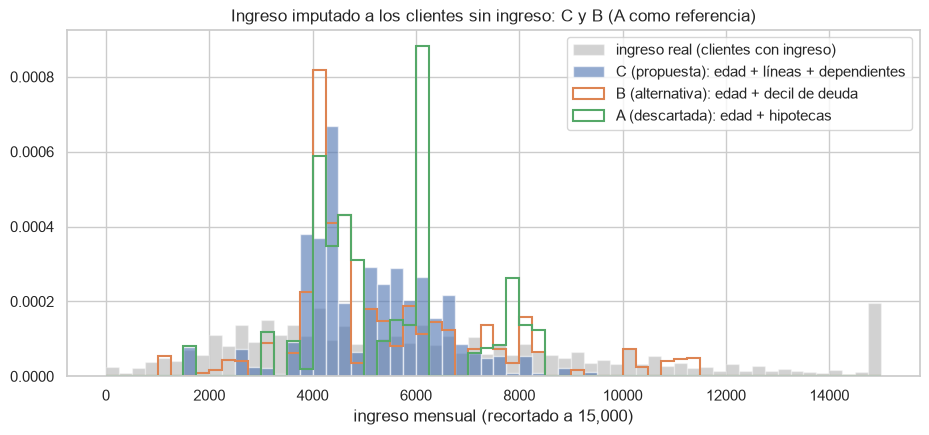

In [31]:
conocidos = base.copy()
cortes_deuda_todos = np.quantile(conocidos["monto_deuda"], np.linspace(0, 1, 11))
cortes_deuda_todos[0], cortes_deuda_todos[-1] = -np.inf, np.inf

sin_ingreso_df = train[falta_ingreso].copy()
sin_ingreso_df["monto_deuda"] = sin_ingreso_df["DebtRatio"]  # ya es el monto
sin_ingreso_df["grupo_edad"] = (
    pd.cut(sin_ingreso_df["age"], CORTES_EDAD, labels=False)
    .fillna(0)
    .astype(int)
    .astype(str)
)
sin_ingreso_df["hipotecas"] = (
    sin_ingreso_df["NumberRealEstateLoansOrLines"].clip(upper=2).astype(str)
)
for df in (conocidos, sin_ingreso_df):
    df["decil_deuda"] = pd.cut(
        df["monto_deuda"], cortes_deuda_todos, labels=False
    ).astype(str)
    df["edad_hipotecas"] = df["grupo_edad"] + "_" + df["hipotecas"]
    df["edad_deuda"] = df["grupo_edad"] + "_" + df["decil_deuda"]

cortes_lineas_todos = cortes_cuantiles(conocidos["NumberOfOpenCreditLinesAndLoans"], 5)
cortes_util_todos = cortes_cuantiles(
    conocidos["RevolvingUtilizationOfUnsecuredLines"], 5
)
for df in (conocidos, sin_ingreso_df):
    agregar_grupos_perfil(df, cortes_lineas_todos, cortes_util_todos)

mediana_conocidos = conocidos["MonthlyIncome"].median()
sin_ingreso_df["income_imp_age_lines_dep"] = imputar_por_niveles(
    conocidos, sin_ingreso_df, NIVELES_C
)
sin_ingreso_df["income_imp_age_mortgage"] = (
    sin_ingreso_df["edad_hipotecas"]
    .map(conocidos.groupby("edad_hipotecas")["MonthlyIncome"].median())
    .fillna(mediana_conocidos)
)
sin_ingreso_df["income_imp_age_debt"] = (
    sin_ingreso_df["edad_deuda"]
    .map(conocidos.groupby("edad_deuda")["MonthlyIncome"].median())
    .fillna(mediana_conocidos)
)

imputados = sin_ingreso_df[
    ["income_imp_age_lines_dep", "income_imp_age_mortgage", "income_imp_age_debt"]
]
display(imputados.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T.round(0))

# ¿Con qué nivel se imputó cada cliente en la estrategia C?
tamanos = {n: conocidos.groupby(n)["MonthlyIncome"].size() for n in NIVELES_C}
nivel_usado = pd.Series("mediana global", index=sin_ingreso_df.index)
for nivel in reversed(NIVELES_C):
    suficiente = sin_ingreso_df[nivel].map(tamanos[nivel]).fillna(0) >= MIN_GRUPO
    nivel_usado[suficiente] = nivel
display(
    (nivel_usado.value_counts(normalize=True) * 100)
    .round(1)
    .rename("% de clientes sin ingreso")
    .rename_axis("nivel usado por C")
    .to_frame()
)

print("Correlación de Spearman entre las variables imputadas:")
display(imputados.corr("spearman").round(3))
for otra in ("income_imp_age_mortgage", "income_imp_age_debt"):
    diferencia_rel = (
        imputados["income_imp_age_lines_dep"] - imputados[otra]
    ).abs() / imputados[otra]
    print(
        f"Clientes donde C difiere más de 30 % de {otra}: "
        f"{(diferencia_rel > 0.3).mean():.1%}"
    )

fig, ax = plt.subplots(figsize=(11, 4.5))
bins = np.linspace(0, 15_000, 61)
ax.hist(conocidos["MonthlyIncome"].clip(upper=15_000), bins=bins, density=True,
        alpha=0.35, color="gray", label="ingreso real (clientes con ingreso)")
ax.hist(imputados["income_imp_age_lines_dep"], bins=bins, density=True, alpha=0.6,
        label="C (propuesta): edad + líneas + dependientes")
ax.hist(imputados["income_imp_age_debt"], bins=bins, density=True,
        histtype="step", lw=1.5, label="B (alternativa): edad + decil de deuda")
ax.hist(imputados["income_imp_age_mortgage"], bins=bins, density=True,
        histtype="step", lw=1.5, label="A (descartada): edad + hipotecas")
ax.set_title("Ingreso imputado a los clientes sin ingreso: C y B (A como referencia)")
ax.set_xlabel("ingreso mensual (recortado a 15,000)")
ax.legend()
plt.show()

**Lectura:**
- **El respaldo casi no se usa:** el 86.6 % de los clientes sin ingreso se
  imputa con el grupo completo (edad × líneas × dependientes) y el 13.4 %
  restante con edad × líneas. Son justo los clientes sin dependientes
  informados. Nadie cae hasta la mediana de la edad sola.
- **C asigna ingresos más bajos:** su mediana es 5,000, contra 5,416 de A.
  Tiene sentido: los clientes sin ingreso tienen menos líneas de crédito
  abiertas (mediana 6 contra 8) y C lo toma en cuenta.
- **C es una variable distinta de A y B:** su correlación de Spearman con
  ellas es 0.65, mientras que A y B se parecen más entre sí (0.84). C difiere
  más de 30 % de A en el 12.6 % de los clientes, y de B en el 22.4 %.
- **C reparte mejor los valores que A:** A se amontona en pocos picos (por
  ejemplo, 6,000) porque solo tiene 33 grupos; C llena el rango de 3,750 a
  6,666 sin picos tan marcados.
- **B es la más repartida** (de 1,200 a 11,359, desviación 1,991 contra
  1,297 de C) y la que más se parece a la forma del ingreso real. Es otra
  razón para conservarla como segunda variable.
- Las tres son más angostas que el ingreso real:
  imputar con medianas siempre reduce la dispersión. Por eso se acompañan
  del indicador `income_missing`.

**e) Detalle del monto mensual de deuda**

El monto mensual de deuda es la base de la estrategia B y del ingreso
disponible, así que conviene conocerlo a fondo. Se construye con la regla de
la sección 10.3 b:
- **Con ingreso > 0:** `DebtRatio × MonthlyIncome`.
- **Sin ingreso o con ingreso = 0:** `DebtRatio` tal cual (ya es el monto).

In [32]:
sin_ingreso_o_cero = train["MonthlyIncome"].isna() | (train["MonthlyIncome"] <= 0)
monto_deuda_todos = train["DebtRatio"].where(
    sin_ingreso_o_cero, train["DebtRatio"] * train["MonthlyIncome"]
)
grupo_ingreso = pd.Series(
    np.select(
        [train["MonthlyIncome"].isna(), train["MonthlyIncome"] == 0],
        ["sin ingreso", "ingreso = 0"],
        default="con ingreso",
    ),
    index=train.index,
)
ORDEN_GRUPOS_INGRESO = ["con ingreso", "sin ingreso", "ingreso = 0"]


def resumen_dispersion(serie: pd.Series) -> pd.Series:
    """Resume la dispersión de una variable numérica.

    Args:
        serie: Valores a resumir.

    Returns:
        Conteo, ceros, tendencia central, dispersión, percentiles y atípicos.
    """
    q1, q3 = serie.quantile([0.25, 0.75])
    limite = q3 + 1.5 * (q3 - q1)
    return pd.Series(
        {
            "registros": len(serie),
            "% en cero": (serie == 0).mean() * 100,
            "media": serie.mean(),
            "mediana": serie.median(),
            "desviación estándar": serie.std(),
            "coeficiente de variación": serie.std() / serie.mean(),
            "p25 (Q1)": q1,
            "p75 (Q3)": q3,
            "p95": serie.quantile(0.95),
            "p99": serie.quantile(0.99),
            "p99.9": serie.quantile(0.999),
            "máximo": serie.max(),
            "límite de atípico (Q3 + 1.5·IQR)": limite,
            "% arriba del límite": (serie > limite).mean() * 100,
            "% de morosidad": train.loc[serie.index, TARGET].mean() * 100,
        }
    )


dispersion_deuda = pd.concat(
    {g: resumen_dispersion(monto_deuda_todos[grupo_ingreso == g]) for g in ORDEN_GRUPOS_INGRESO}
    | {"todos": resumen_dispersion(monto_deuda_todos)},
    axis=1,
)
dispersion_deuda.round(2)

,con ingreso,sin ingreso,ingreso = 0,todos
registros,83029.00,20828.00,1143.00,105000.00
% en cero,2.05,5.58,5.60,2.79
media,2139.11,1702.83,1476.65,2045.36
mediana,1648.81,1158.00,940.00,1545.72
desviación estándar,4200.10,4928.66,1984.92,4341.02
coeficiente de variación,1.96,2.89,1.34,2.12
p25 (Q1),630.92,120.00,95.00,527.91
p75 (Q3),2896.97,2389.00,2186.00,2795.74
p95,5605.71,4940.65,4654.90,5469.80
p99,9451.22,8198.19,9134.00,9214.01


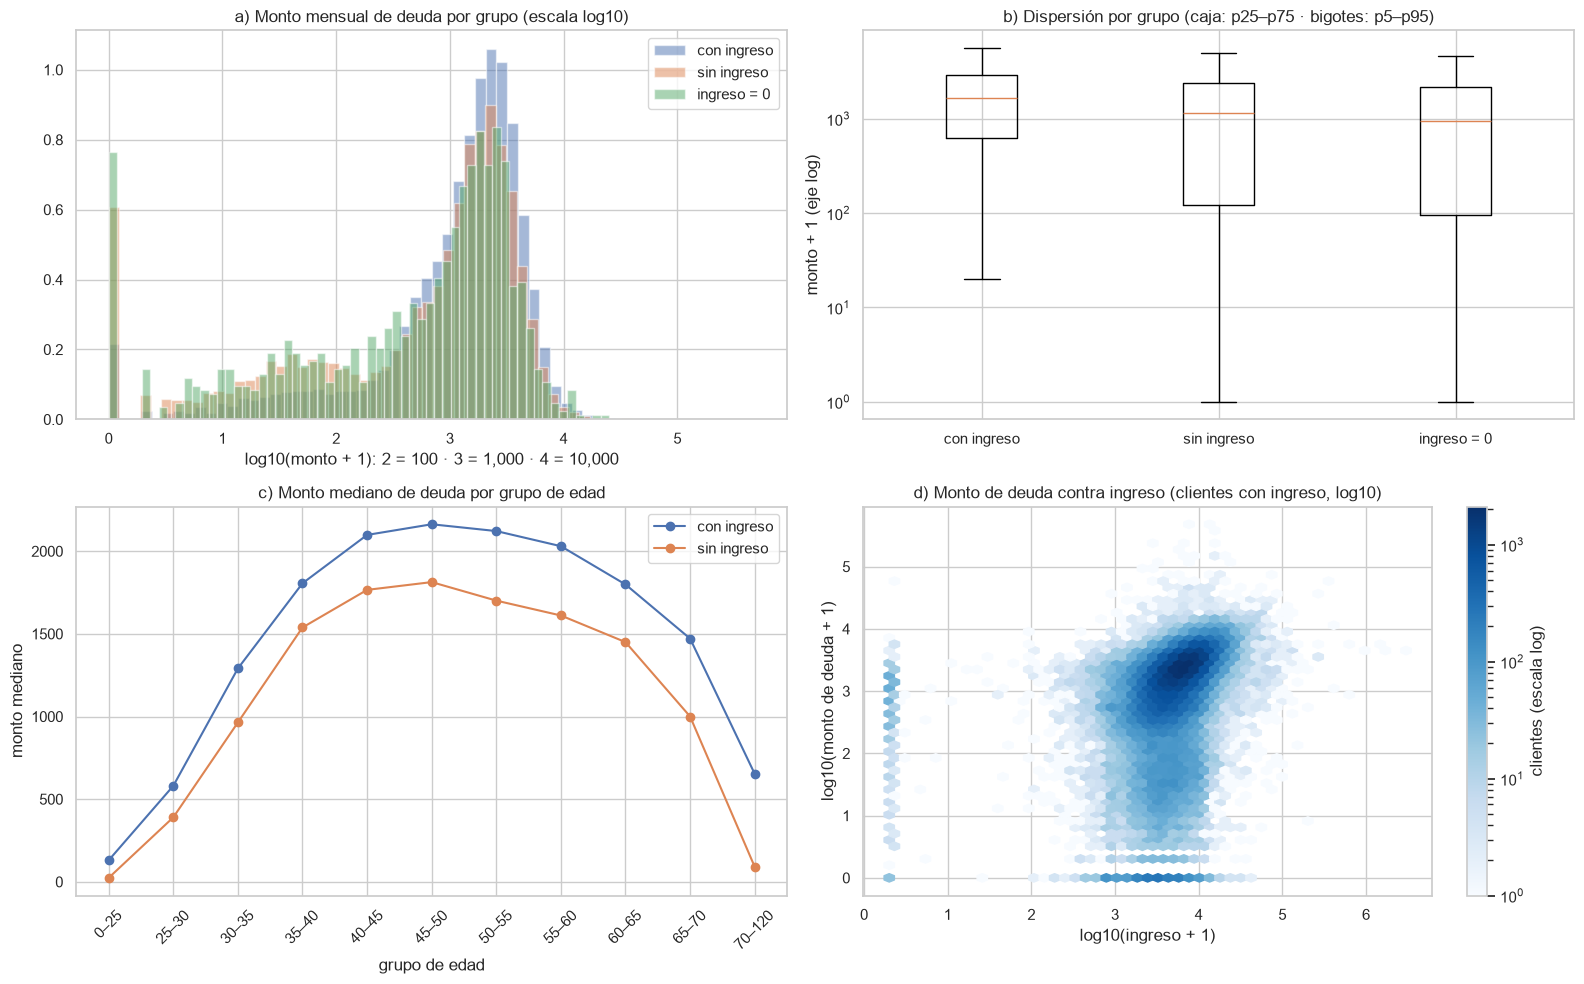

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# a) Distribución en escala log por grupo
ax = axes[0, 0]
for g in ORDEN_GRUPOS_INGRESO:
    ax.hist(np.log10(monto_deuda_todos[grupo_ingreso == g] + 1), bins=60, density=True,
            alpha=0.5, label=g)
ax.set_title("a) Monto mensual de deuda por grupo (escala log10)")
ax.set_xlabel("log10(monto + 1): 2 = 100 · 3 = 1,000 · 4 = 10,000")
ax.legend()

# b) Caja por grupo
ax = axes[0, 1]
ax.boxplot(
    [monto_deuda_todos[grupo_ingreso == g].to_numpy() + 1 for g in ORDEN_GRUPOS_INGRESO],
    tick_labels=ORDEN_GRUPOS_INGRESO,
    whis=(5, 95),
    showfliers=False,
)
ax.set_yscale("log")
ax.set_title("b) Dispersión por grupo (caja: p25–p75 · bigotes: p5–p95)")
ax.set_ylabel("monto + 1 (eje log)")

# c) Monto mediano por grupo de edad
ax = axes[1, 0]
for g in ["con ingreso", "sin ingreso"]:
    mascara_g = grupo_ingreso == g
    medianas = monto_deuda_todos[mascara_g].groupby(
        pd.cut(train.loc[mascara_g, "age"], CORTES_EDAD), observed=True
    ).median()
    ax.plot([f"{int(i.left)}–{int(i.right)}" for i in medianas.index], medianas.values,
            marker="o", label=g)
ax.set_title("c) Monto mediano de deuda por grupo de edad")
ax.set_xlabel("grupo de edad")
ax.set_ylabel("monto mediano")
ax.tick_params(axis="x", rotation=45)
ax.legend()

# d) Monto de deuda contra ingreso (clientes con ingreso)
ax = axes[1, 1]
con = grupo_ingreso == "con ingreso"
hb = ax.hexbin(
    np.log10(train.loc[con, "MonthlyIncome"] + 1),
    np.log10(monto_deuda_todos[con] + 1),
    gridsize=50, bins="log", cmap="Blues", mincnt=1,
)
ax.set_title("d) Monto de deuda contra ingreso (clientes con ingreso, log10)")
ax.set_xlabel("log10(ingreso + 1)")
ax.set_ylabel("log10(monto de deuda + 1)")
fig.colorbar(hb, ax=ax, label="clientes (escala log)")

plt.tight_layout()
plt.show()

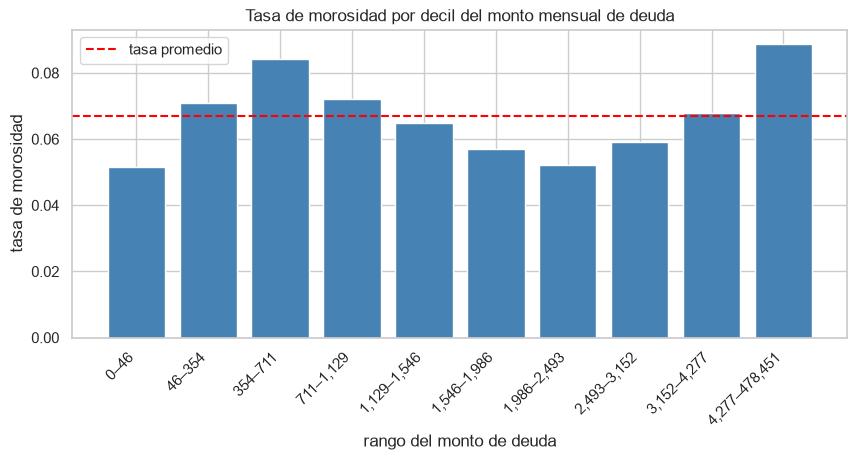

Clientes con deuda = 0: 2,925 · tasa de morosidad 0.086
Spearman monto de deuda vs ingreso (con ingreso): 0.498


,monto mínimo,monto máximo,tasa de morosidad
decil,,,
0,0.000,45.847,0.052
1,45.929,354.000,0.071
2,354.000,710.744,0.084
3,710.763,1128.839,0.072
4,1128.839,1545.724,0.065
5,1545.724,1985.809,0.057
6,1985.860,2492.797,0.052
7,2492.850,3151.516,0.059
8,3151.606,4277.321,0.068


In [34]:
# ¿El monto de deuda separa morosos?
deciles_monto = pd.qcut(monto_deuda_todos.rank(method="first"), 10, labels=False)
por_decil = pd.DataFrame(
    {
        "monto mínimo": monto_deuda_todos.groupby(deciles_monto).min(),
        "monto máximo": monto_deuda_todos.groupby(deciles_monto).max(),
        "tasa de morosidad": train[TARGET].groupby(deciles_monto).mean(),
    }
).rename_axis("decil")

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(por_decil.index, por_decil["tasa de morosidad"], color="steelblue")
ax.axhline(train[TARGET].mean(), color="red", ls="--", label="tasa promedio")
ax.set_xticks(por_decil.index)
ax.set_xticklabels(
    [f"{a:,.0f}–{b:,.0f}" for a, b in zip(por_decil["monto mínimo"], por_decil["monto máximo"])],
    rotation=45, ha="right",
)
ax.set_title("Tasa de morosidad por decil del monto mensual de deuda")
ax.set_xlabel("rango del monto de deuda")
ax.set_ylabel("tasa de morosidad")
ax.legend()
plt.show()

print(f"Clientes con deuda = 0: {(monto_deuda_todos == 0).sum():,} "
      f"· tasa de morosidad {train.loc[monto_deuda_todos == 0, TARGET].mean():.3f}")
print("Spearman monto de deuda vs ingreso (con ingreso):",
      round(monto_deuda_todos[con].corr(train.loc[con, "MonthlyIncome"], method="spearman"), 3))
por_decil.round(3)

In [35]:
# Valores extremos
extremos = pd.DataFrame(
    {
        "monto_deuda": monto_deuda_todos,
        "grupo": grupo_ingreso,
        "MonthlyIncome": train["MonthlyIncome"],
        "DebtRatio": train["DebtRatio"],
        TARGET: train[TARGET],
    }
)
print("Monto > 20,000:", (monto_deuda_todos > 20_000).sum(),
      "· monto > 50,000:", (monto_deuda_todos > 50_000).sum())
print(f"Asimetría: {monto_deuda_todos.skew():.1f} · con log1p: "
      f"{np.log1p(monto_deuda_todos).skew():.2f}")
extremos.nlargest(8, "monto_deuda").round(2)

Monto > 20,000: 162 · monto > 50,000: 46
Asimetría: 56.5 · con log1p: -1.75


,monto_deuda,grupo,MonthlyIncome,DebtRatio,SeriousDlqin2yrs
42075,478450.56,con ingreso,13500.0,35.44,1
38916,474639.29,con ingreso,7223.0,65.71,0
35223,422571.83,con ingreso,15000.0,28.17,0
42243,329664.00,sin ingreso,NaN,329664.00,0
25741,326442.00,sin ingreso,NaN,326442.00,0
88950,307001.00,sin ingreso,NaN,307001.00,0
74373,247877.70,con ingreso,2601.0,95.30,1
55137,244826.16,con ingreso,16500.0,14.84,0


**Lectura:**
- **Muy disperso, igual que el ingreso:** mediana de 1,546 al mes, pero
  máximo de 478,451 (más de 300 veces la mediana); coeficiente de variación
  2.1 y asimetría 56. Con `log1p` la asimetría baja a −1.75, así que el
  `log1p` es obligatorio para modelos lineales.
- **Clientes sin ingreso deben menos:** mediana de 1,158 contra 1,649 de los
  que tienen ingreso, y su distribución tiene más montos bajos (p25 de 120
  contra 631). Es coherente con perfiles de menor actividad crediticia.
- **La deuda sigue el ciclo de vida:** sube hasta la edad media y baja en los
  mayores (gráfica c), en ambos grupos.
- **Se relaciona con el ingreso** (Spearman 0.50, gráfica d): quien gana más
  tiende a deber más. Por eso sirve para inferir el ingreso (estrategia B).
- **Por sí solo separa poco a los morosos:** la relación tiene **forma de
  U**. El riesgo sube en montos bajos a medios (46 a 1,129: hasta 8.4 %),
  baja en el centro (5.2 % entre 1,986 y 2,493) y vuelve a subir en el decil
  más alto (más de 4,277: 8.9 %). Dentro del primer decil hay un contraste:
  los 2,925 clientes con deuda exactamente 0 tienen 8.6 % de morosidad,
  mientras que el resto de ese decil (1 a 46) es de bajo riesgo. Una
  regresión logística no capta una U con la variable cruda; WoE o los
  árboles sí.
- **Su valor está en combinación con el ingreso:** el ingreso disponible
  (ingreso − monto de deuda) tiene casi el doble de IV que el ingreso solo
  (sección 10.8 b).
- **Extremos:** 162 clientes deben más de 20,000 al mes y 46 más de 50,000;
  el p99.9 es ~27,300. Algunos son inverosímiles (deber 478,451 al mes con un
  ingreso de 13,500): errores de captura. Con `log1p` no hace falta
  recortarlos; una alternativa a probar es recortar en el p99.9.
- **Hallazgo: el ingreso = 1 es un valor de relleno.** La franja
  vertical de la gráfica d (log10 ≈ 0.3) son **423 clientes con ingreso
  exactamente 1**. Su `DebtRatio` mediano es 625 y el 94 % supera 1: como
  con el ingreso faltante, ahí `DebtRatio` es el monto de la deuda. Su monto
  queda bien calculado (`DebtRatio × 1`), pero su "ingreso" no es real y
  distorsiona el ingreso disponible (1 − deuda). **Propuesta:** tratar el
  ingreso = 1 igual que el ingreso = 0 (indicador propio y excluirlo al
  aprender las medianas de imputación). En el módulo es el indicador
  `income_placeholder`.

**f) Influencia de los dependientes económicos**

`NumberOfDependents` es el número de personas que dependen económicamente
del cliente (sin contarlo a él). Preguntas:
1. ¿Más dependientes implica más riesgo?
2. ¿El efecto es real o se debe a la edad o al ingreso?
3. ¿Cómo aprovecharlo en la ingeniería de variables?

La señal se mide con el **Information Value (IV)**, que se explica a
detalle en la sección 10.8 a.

,clientes,tasa_morosidad,% de clientes,IC 95 % (±)
NumberOfDependents,,,,
0,60792,0.0586,57.8971,0.0019
1,18479,0.0722,17.5990,0.0037
2,13587,0.0821,12.9400,0.0046
3,6695,0.0913,6.3762,0.0069
4,1980,0.0965,1.8857,0.0130
5+,696,0.1006,0.6629,0.0223
faltante,2771,0.0480,2.6390,0.0080


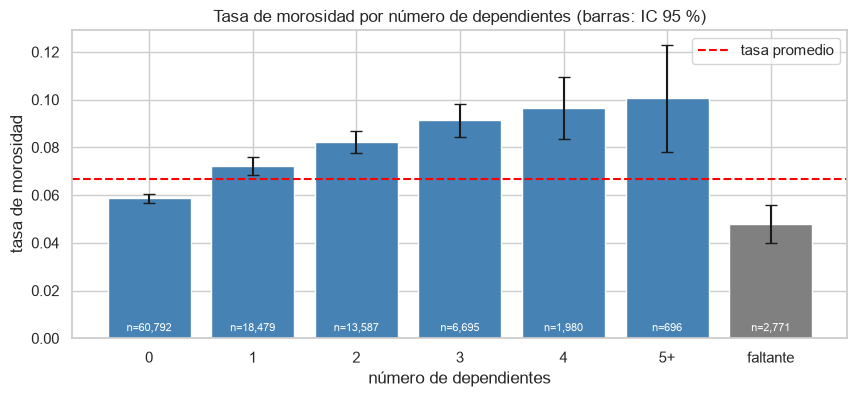

IV de NumberOfDependents: 0.035


In [36]:
def information_value(valores: pd.Series, objetivo: pd.Series, n_rangos: int = 10) -> float:
    """Calcula el Information Value de una variable cortada en cuantiles.

    Los valores faltantes forman un rango propio. Se suma 0.5 a cada conteo
    para evitar divisiones entre cero.

    Args:
        valores: Variable a evaluar.
        objetivo: Variable objetivo binaria (1 = moroso).
        n_rangos: Número de rangos por cuantiles.

    Returns:
        Information Value de la variable.
    """
    if valores.nunique() > n_rangos:
        rangos = pd.qcut(valores.rank(method="first"), n_rangos, labels=False)
    else:
        rangos = valores
    rangos = rangos.astype(float).fillna(-1)
    conteos = pd.crosstab(rangos, objetivo) + 0.5
    pct_morosos = conteos[1] / conteos[1].sum()
    pct_no_morosos = conteos[0] / conteos[0].sum()
    woe = np.log(pct_no_morosos / pct_morosos)
    return float(((pct_no_morosos - pct_morosos) * woe).sum())


dependientes = train["NumberOfDependents"].clip(upper=5)
etiqueta_dep = dependientes.map(
    lambda v: "5+" if v == 5 else f"{v:.0f}", na_action="ignore"
).fillna("faltante")
ORDEN_DEP = ["0", "1", "2", "3", "4", "5+", "faltante"]

tabla_dep = (
    train.groupby(etiqueta_dep)[TARGET]
    .agg(clientes="count", tasa_morosidad="mean")
    .reindex(ORDEN_DEP)
)
tabla_dep["% de clientes"] = tabla_dep["clientes"] / len(train) * 100
tabla_dep["IC 95 % (±)"] = 1.96 * np.sqrt(
    tabla_dep["tasa_morosidad"] * (1 - tabla_dep["tasa_morosidad"]) / tabla_dep["clientes"]
)
display(tabla_dep.round(4))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(tabla_dep.index, tabla_dep["tasa_morosidad"], yerr=tabla_dep["IC 95 % (±)"],
       color=["steelblue"] * 6 + ["gray"], capsize=4)
ax.axhline(train[TARGET].mean(), color="red", ls="--", label="tasa promedio")
for i, n in enumerate(tabla_dep["clientes"]):
    ax.text(i, 0.003, f"n={n:,}", ha="center", fontsize=8, color="white")
ax.set_title("Tasa de morosidad por número de dependientes (barras: IC 95 %)")
ax.set_xlabel("número de dependientes")
ax.set_ylabel("tasa de morosidad")
ax.legend()
plt.show()
print(f"IV de NumberOfDependents: {information_value(dependientes, train[TARGET]):.3f}")

**¿Es efecto de los dependientes o de la edad y el ingreso?** Los
dependientes se relacionan con la edad (los adultos de 35 a 50 años tienen
más) y con el ingreso. Se revisa la morosidad **dentro** de cada grupo de
edad y de cada cuartil de ingreso. Se ocultan las celdas con menos de 100
clientes.

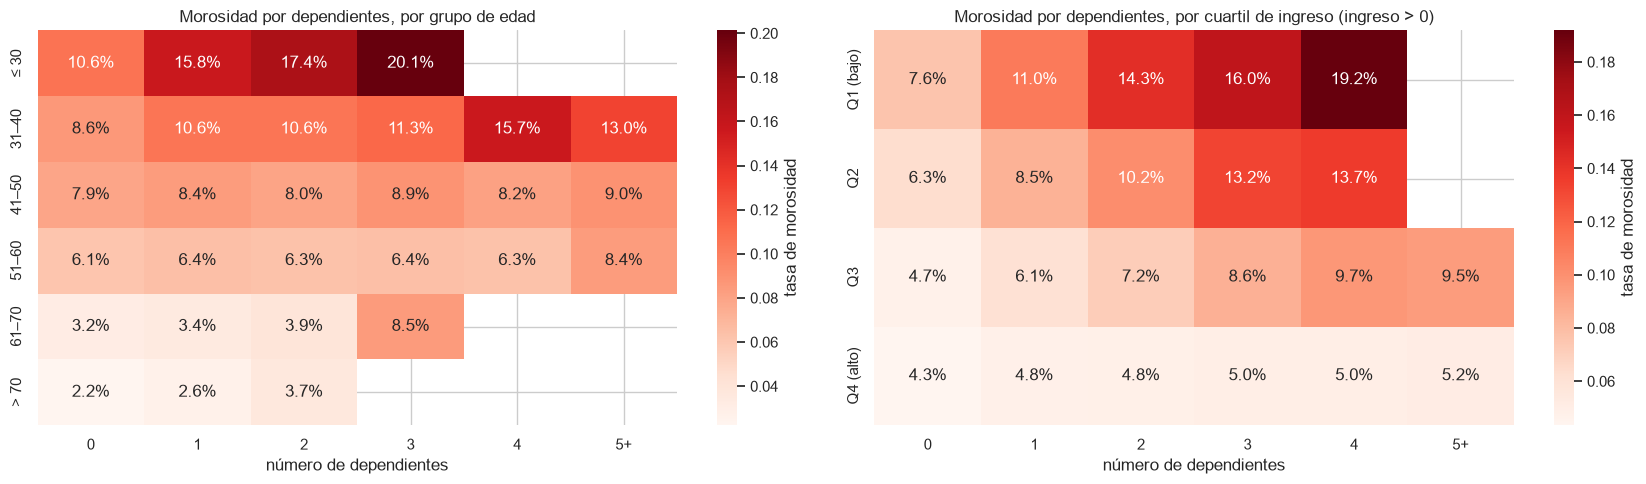

In [37]:
edad_amplia = pd.cut(train["age"], [0, 30, 40, 50, 60, 70, 120], include_lowest=True)
edad_amplia = edad_amplia.cat.rename_categories(
    ["≤ 30", "31–40", "41–50", "51–60", "61–70", "> 70"]
)
cuartil_ingreso = pd.qcut(
    train["MonthlyIncome"].where(train["MonthlyIncome"] > 0), 4,
    labels=["Q1 (bajo)", "Q2", "Q3", "Q4 (alto)"],
)
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for ax, filas, titulo in [
    (axes[0], edad_amplia, "por grupo de edad"),
    (axes[1], cuartil_ingreso, "por cuartil de ingreso (ingreso > 0)"),
]:
    tasas = train.pivot_table(index=filas, columns=dependientes, values=TARGET,
                              aggfunc="mean", observed=True)
    conteos = train.pivot_table(index=filas, columns=dependientes, values=TARGET,
                                aggfunc="count", observed=True)
    tasas.columns = ["0", "1", "2", "3", "4", "5+"]
    sns.heatmap(tasas.where(conteos.to_numpy() >= 100), annot=True, fmt=".1%",
                cmap="Reds", ax=ax, cbar_kws={"label": "tasa de morosidad"})
    ax.set_title(f"Morosidad por dependientes, {titulo}")
    ax.set_xlabel("número de dependientes")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [38]:
# Efecto "neto" con una regresión logística sencilla (variables estandarizadas)
from sklearn.linear_model import LogisticRegression

con_datos = dependientes.notna() & (train["MonthlyIncome"] > 0)
explicativas = pd.DataFrame(
    {
        "dependientes": dependientes[con_datos],
        "edad": train.loc[con_datos, "age"],
        "log ingreso": np.log1p(train.loc[con_datos, "MonthlyIncome"].clip(upper=25_000)),
    }
)
explicativas = (explicativas - explicativas.mean()) / explicativas.std()
efecto_neto = {}
for columnas in [["dependientes"], ["dependientes", "edad"],
                 ["dependientes", "edad", "log ingreso"]]:
    modelo = LogisticRegression().fit(explicativas[columnas], train.loc[con_datos, TARGET])
    efecto_neto[" + ".join(columnas)] = modelo.coef_[0][0]
pd.Series(efecto_neto, name="coeficiente de dependientes").round(3).to_frame()

,coeficiente de dependientes
dependientes,0.170
dependientes + edad,0.112
dependientes + edad + log ingreso,0.129


**Ingreso por dependiente:** si los dependientes pesan más cuando el ingreso
es bajo, la variable natural es cuánto ingreso le toca a cada miembro del
hogar: `ingreso / (1 + dependientes)`.

,IV (clientes con ingreso > 0 y dependientes informados)
NumberOfDependents,0.034
MonthlyIncome,0.088
ingreso por dependiente,0.125


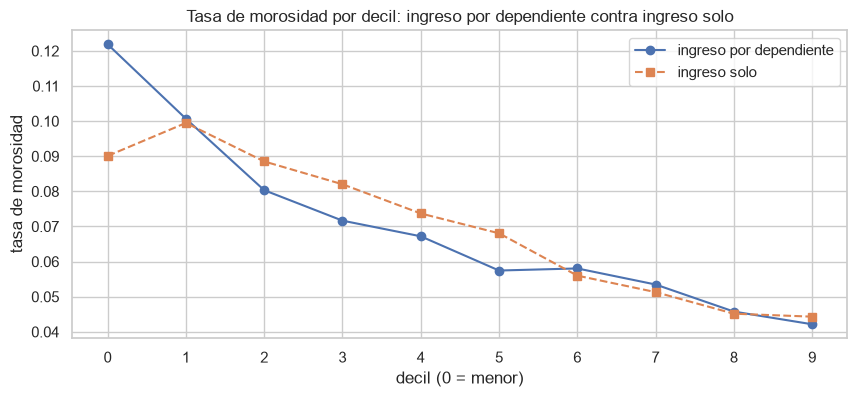

In [39]:
base_ipd = train[con_datos].copy()
base_ipd["ingreso_por_dependiente"] = base_ipd["MonthlyIncome"] / (
    1 + base_ipd["NumberOfDependents"]
)
iv_dependientes = pd.Series(
    {
        "NumberOfDependents": information_value(
            base_ipd["NumberOfDependents"].clip(upper=5), base_ipd[TARGET]
        ),
        "MonthlyIncome": information_value(base_ipd["MonthlyIncome"], base_ipd[TARGET]),
        "ingreso por dependiente": information_value(
            base_ipd["ingreso_por_dependiente"], base_ipd[TARGET]
        ),
    },
    name="IV (clientes con ingreso > 0 y dependientes informados)",
)
display(iv_dependientes.round(3).to_frame())

deciles_ipd = pd.qcut(base_ipd["ingreso_por_dependiente"].rank(method="first"), 10,
                      labels=False)
deciles_ing = pd.qcut(base_ipd["MonthlyIncome"].rank(method="first"), 10, labels=False)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(base_ipd.groupby(deciles_ipd)[TARGET].mean(), marker="o",
        label="ingreso por dependiente")
ax.plot(base_ipd.groupby(deciles_ing)[TARGET].mean(), marker="s", ls="--",
        label="ingreso solo")
ax.set_title("Tasa de morosidad por decil: ingreso por dependiente contra ingreso solo")
ax.set_xlabel("decil (0 = menor)")
ax.set_ylabel("tasa de morosidad")
ax.set_xticks(range(10))
ax.legend()
plt.show()

**Lectura:**
- **Más dependientes, más riesgo, de forma ordenada:** la morosidad sube de
  5.9 % sin dependientes a 7.2 % (1), 8.2 % (2), 9.1 % (3), 9.7 % (4) y
  10.1 % (5 o más). Los intervalos de confianza de 0, 1, 2 y 3 no se
  traslapan, así que la diferencia es real.
- **Los clientes sin el dato tienen el menor riesgo (4.8 %)**. Son los
  mismos que no reportan ingreso (sección 10.3 a): el indicador
  `dependents_missing` captura esa diferencia.
- **Por sí sola es una variable débil (IV 0.035)** porque el 58 % de los
  clientes no tiene dependientes.
- **El efecto es real, no solo de la edad o el ingreso:** su coeficiente baja
  de 0.17 a 0.11 al controlar por edad, pero se mantiene (0.13) al agregar el
  ingreso.
- **Pero depende del contexto (interacción):**
  - En **jóvenes (≤ 30)** la morosidad se dispara: de 10.6 % sin
    dependientes a 20.1 % con 3.
  - En el **cuartil de ingreso más bajo** pasa de 7.6 % a 19.2 % con 4.
  - En el **cuartil de ingreso más alto** casi no cambia (4.3 % a 5.2 %), y
    entre 41 y 60 años tampoco.
  - Los dependientes pesan **cuando los recursos son escasos**.
- **Por eso el ingreso por dependiente es mejor variable:** IV de **0.125**
  contra 0.088 del ingreso solo y 0.035 de los dependientes, con una
  relación más limpia (de 12.2 % en el decil más bajo a 4.2 % en el más
  alto).

**Propuesta para la ingeniería de variables:**
- Conservar `dependents` (recortado a 5) y `dependents_missing`.
- **Agregar el ingreso por dependiente** = ingreso imputado /
  (1 + dependientes). En el módulo es `per_dependent_<ingreso>`, una columna
  por cada variable de ingreso imputado. **Resultado en el notebook 03:** no
  mejora la regresión logística (+0.0002 de AUC al quitarla) y aporta muy
  poco a los árboles (+0.0003). Su buen IV no se traduce en AUC porque el
  modelo ya tiene el ingreso y los dependientes por separado.
- Para modelos lineales, probar la interacción joven × dependientes; los
  árboles la encuentran solos.

### 10.4 Atípicos que se corrigen antes de imputar o escalar

In [40]:
rangos_util = pd.cut(
    train["RevolvingUtilizationOfUnsecuredLines"], [-1, 0.3, 0.7, 1, 2, 10, np.inf]
)
display(
    train.groupby(rangos_util, observed=True)[TARGET]
    .agg(clientes="count", tasa_morosidad="mean")
    .round(3)
)
print("Edad < 18:", (train["age"] < 18).sum())
print("Ingreso = 0:", (train["MonthlyIncome"] == 0).sum())
print("Filas con atrasos 96/98:", (train[LATE] >= 96).any(axis=1).sum())
print("Atraso máximo real (sin 96/98):", train.loc[~codigo, LATE].max().to_dict())

,clientes,tasa_morosidad
RevolvingUtilizationOfUnsecuredLines,,
"(-1.0, 0.3]",64955,0.022
"(0.3, 0.7]",19047,0.074
"(0.7, 1.0]",18682,0.178
"(1.0, 2.0]",2051,0.396
"(2.0, 10.0]",92,0.304
"(10.0, inf]",173,0.064


Edad < 18: 1
Ingreso = 0: 1143
Filas con atrasos 96/98: 197
Atraso máximo real (sin 96/98): {'NumberOfTime30-59DaysPastDueNotWorse': 13, 'NumberOfTime60-89DaysPastDueNotWorse': 11, 'NumberOfTimes90DaysLate': 15}


**Lectura:**
- **Utilización:** el riesgo sube hasta 1–2 (40 % de morosidad) y luego
  **baja** para valores > 10 (6 %). Esos valores no son utilizaciones reales,
  son errores de captura. Recortar en 2 conserva la señal; un indicador
  `util_gt1` captura el exceso.
- **Edad < 18:** solo hay un registro (edad 0). Se pone en `NaN` y se imputa.
- **Ingreso = 0:** 1,143 clientes. No es faltante, pero hace infinita la
  razón de deuda; lleva su propio indicador.
- **Atrasos 96/98:** 197 filas, siempre en las tres columnas a la vez. Se
  ponen en `NaN` con indicador `late_sentinel`; el atraso real máximo es 15.

### 10.5 Escalado propuesto
El escalado solo lo necesitan los modelos que usan coeficientes o
distancias, en este caso la **regresión logística con regularización**
(L1/L2 penaliza por igual a todos los coeficientes, así que las variables
deben estar en la misma escala). Los **modelos de árboles no se escalan**.

| Técnica | Papel | Dónde se usa |
| --- | --- | --- |
| `log1p` | Paso previo: comprime la cola larga | Ingreso, `DebtRatio`, monto de deuda y atrasos |
| `StandardScaler` (estandarizar) | **Opción base**: media 0 y desviación 1 | Todas las variables continuas, después de recortar y `log1p` |
| `RobustScaler` | Comparación: usa mediana e IQR, resiste atípicos | Experimento contra `StandardScaler` (no en atrasos: su IQR es 0) |
| `QuantileTransformer` | Comparación: convierte a percentiles | Experimento contra `StandardScaler` |

### 10.6 Propuesta por variable
Orden de aplicación: **1) limpieza fija → 2) imputación → 3) transformación
→ 4) escalado**. Los pasos 2 y 4 se aprenden en cada pliegue.

| Variable | Problema detectado | Faltantes | Atípicos (fijo) | Transformación | Escalado | Alternativa a probar |
| --- | --- | --- | --- | --- | --- | --- |
| `RevolvingUtilizationOfUnsecuredLines` | Asimetría 98; valores > 10 son errores | — | Recortar a [0, 2] + `util_gt1` | — | `StandardScaler` | `QuantileTransformer` |
| `age` | 1 registro con edad 0 | Mediana (1 fila) | Edad < 18 → `NaN` | — | `StandardScaler` | — |
| `NumberOfTime30-59DaysPastDueNotWorse` | 84 % ceros; códigos 96/98 | 96/98 → 0 + `late_sentinel` | 96/98 → `NaN` | Recortar a p99.9 + `log1p` | `StandardScaler` | Binarizar (0 / ≥ 1) |
| `NumberOfTime60-89DaysPastDueNotWorse` | 95 % ceros; códigos 96/98 | Igual que arriba | Igual que arriba | Igual que arriba | `StandardScaler` | Igual que arriba |
| `NumberOfTimes90DaysLate` | 94 % ceros; códigos 96/98 | Igual que arriba | Igual que arriba | Igual que arriba | `StandardScaler` | Igual que arriba |
| `DebtRatio` | Es un **monto** cuando falta el ingreso | — | Separar en `debt_ratio_valid` (≤ 10) y `debt_amount` | `log1p` a ambas | `StandardScaler` | `RobustScaler` |
| `MonthlyIncome` | 19.8 % faltante; 1,143 en 0; muy disperso (CV 2.3) | ⭐ `income_imp_age_lines_dep` (estrategia C: edad + líneas de crédito + dependientes, con respaldo) + `income_missing` | Recortar a p99 (25,000) + `income_zero` + `income_placeholder` (ingreso = 1) | `log1p`; derivadas: ingreso disponible e ingreso por dependiente | `StandardScaler` | 🔷 `income_imp_age_debt` (estrategia B: edad + decil de deuda) como segunda variable; usar solo C, solo B o ambas |
| `NumberOfOpenCreditLinesAndLoans` | Asimetría moderada (1.2) | — | Recortar a p99 (24) | — | `StandardScaler` | — |
| `NumberRealEstateLoansOrLines` | Máximo 54 contra p99 de 4 | — | Recortar a 5 | — | `StandardScaler` | — |
| `NumberOfDependents` | 2.6 % faltante (siempre junto con ingreso) | Mediana por grupo de edad (0 o 1) + `dependents_missing` | Recortar a 5 | — | `StandardScaler` | Imputar 0 (la moda) |

**Para modelos de árboles** (XGBoost, `HistGradientBoostingClassifier`):
misma limpieza fija y mismos indicadores, **sin escalado**. Estos modelos
manejan `NaN` directamente, así que imputar es opcional: conviene comparar
ambas opciones.

### 10.7 PCA: ¿dónde está el jugo en los datos?
El **Análisis de Componentes Principales (PCA)** combina las variables en
nuevos ejes, los *componentes principales*, ordenados de mayor a menor
varianza. El primer componente es la dirección donde los datos más varían,
es decir, donde hay **más jugo en los datos**; el segundo es la siguiente, y
así sucesivamente.

Como PCA mide varianza, se aplica sobre los datos ya preparados según la
propuesta: limpieza fija, imputación sencilla con la mediana, `log1p` y
`StandardScaler`. Sin escalar, el ingreso (en miles) dominaría solo por su
escala.

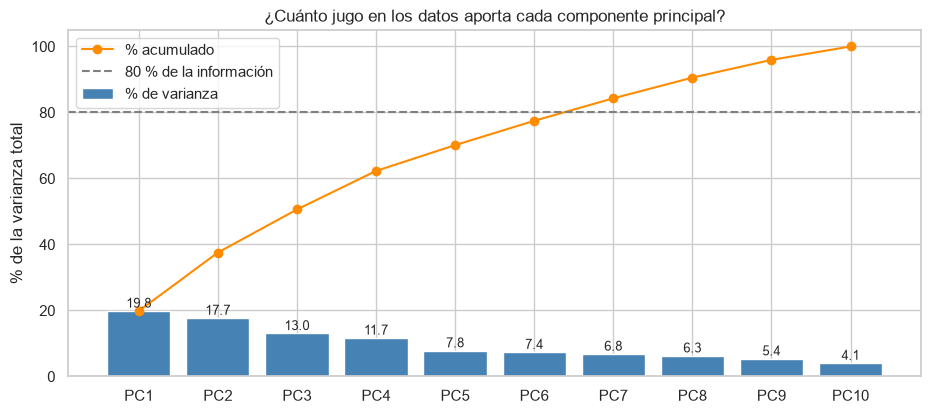

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
% varianza,19.8,17.7,13.0,11.7,7.8,7.4,6.8,6.3,5.4,4.1
% acumulado,19.8,37.6,50.6,62.3,70.1,77.5,84.3,90.6,95.9,100.0


In [41]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

datos_pca = train[FEATS].copy()
datos_pca[LATE] = datos_pca[LATE].where(datos_pca[LATE] < 96, 0)
datos_pca.loc[datos_pca["age"] < 18, "age"] = np.nan
datos_pca["RevolvingUtilizationOfUnsecuredLines"] = datos_pca[
    "RevolvingUtilizationOfUnsecuredLines"
].clip(0, 2)
sin_ingreso = datos_pca["MonthlyIncome"].isna() | (datos_pca["MonthlyIncome"] <= 0)
datos_pca["DebtRatio"] = datos_pca["DebtRatio"].where(~sin_ingreso).clip(upper=10)
datos_pca["MonthlyIncome"] = datos_pca["MonthlyIncome"].clip(upper=25_000)
datos_pca["NumberOfOpenCreditLinesAndLoans"] = datos_pca[
    "NumberOfOpenCreditLinesAndLoans"
].clip(upper=24)
datos_pca["NumberRealEstateLoansOrLines"] = datos_pca[
    "NumberRealEstateLoansOrLines"
].clip(upper=5)
datos_pca["NumberOfDependents"] = datos_pca["NumberOfDependents"].clip(upper=5)
datos_pca = datos_pca.fillna(datos_pca.median())
COLS_LOG = LATE + ["DebtRatio", "MonthlyIncome"]
datos_pca[COLS_LOG] = np.log1p(datos_pca[COLS_LOG])

matriz = StandardScaler().fit_transform(datos_pca)
pca = PCA(random_state=42).fit(matriz)
varianza = pd.DataFrame(
    {
        "% varianza": pca.explained_variance_ratio_ * 100,
        "% acumulado": pca.explained_variance_ratio_.cumsum() * 100,
    },
    index=[f"PC{i}" for i in range(1, len(FEATS) + 1)],
)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(varianza.index, varianza["% varianza"], color="steelblue", label="% de varianza")
ax.plot(varianza.index, varianza["% acumulado"], color="darkorange", marker="o",
        label="% acumulado")
ax.axhline(80, color="gray", ls="--", label="80 % de la información")
for i, v in enumerate(varianza["% varianza"]):
    ax.text(i, v + 1, f"{v:.1f}", ha="center", fontsize=9)
ax.set_title("¿Cuánto jugo en los datos aporta cada componente principal?")
ax.set_ylabel("% de la varianza total")
ax.legend()
plt.show()
varianza.round(1).T

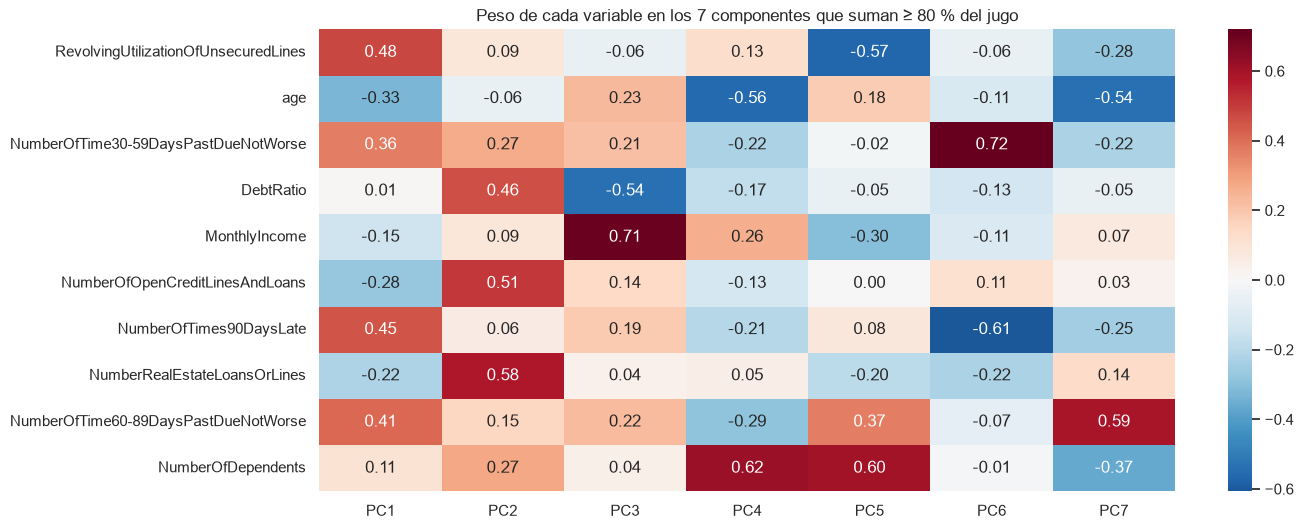

Componentes necesarios para llegar a 80 % de la varianza: 7 de 10


In [42]:
n_80 = int((varianza["% acumulado"] < 80).sum() + 1)
cargas = pd.DataFrame(
    pca.components_[:n_80].T,
    index=FEATS,
    columns=[f"PC{i}" for i in range(1, n_80 + 1)],
)
fig, ax = plt.subplots(figsize=(1.4 * n_80 + 4, 6))
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title(f"Peso de cada variable en los {n_80} componentes que suman ≥ 80 % del jugo")
plt.show()
print(f"Componentes necesarios para llegar a 80 % de la varianza: {n_80} de {len(FEATS)}")

**Guía de las gráficas:**
- **Barras:** cuánta varianza explica cada componente. La línea naranja es
  el acumulado: dónde cruza el 80 % indica cuántos componentes concentran
  casi todo el jugo en los datos.
- **Mapa de calor:** cuánto pesa cada variable en cada componente. Colores
  intensos (rojo o azul) son las variables que "forman" ese componente; el
  signo indica si se mueven en la misma dirección o en direcciones opuestas.

**Lectura: ¿dónde está el jugo en los datos?**

| Componente | % del jugo | Variables que lo forman | Interpretación |
| --- | --- | --- | --- |
| **PC1** | **19.8 %** | Utilización (+0.48), atrasos 90+ (+0.45), 60–89 (+0.41), 30–59 (+0.36), edad (−0.33) | **Riesgo de pago:** clientes jóvenes, con líneas muy usadas y atrasos |
| **PC2** | **17.7 %** | Hipotecas (+0.58), líneas abiertas (+0.51), `DebtRatio` (+0.46) | **Tamaño del perfil crediticio:** cuánto crédito tiene el cliente |
| **PC3** | 13.0 % | Ingreso (+0.71), `DebtRatio` (−0.54) | **Capacidad de pago:** más ingreso con menos endeudamiento relativo |
| **PC4** | 11.7 % | Dependientes (+0.62), edad (−0.56) | **Etapa de vida:** familia joven con dependientes |

- Los dos primeros componentes juntan el **37.6 %** del jugo en los datos y
  los cuatro primeros, el **62.3 %**.
- Para llegar al 80 % se necesitan **7 de 10 componentes**: la información
  está repartida y las variables casi no son redundantes. **Reducir
  dimensiones con PCA no conviene** en este problema; mejor conservar las
  variables originales y las construidas.

**¿El jugo sirve para predecir?** PCA mide **varianza**, no capacidad para
separar morosos. Para comprobarlo se mide el AUC de cada componente por sí
solo:

In [43]:
from sklearn.metrics import roc_auc_score

componentes = pca.transform(matriz)
auc_componentes = pd.Series(
    {
        f"PC{i + 1}": max(
            roc_auc_score(train[TARGET], componentes[:, i]),
            1 - roc_auc_score(train[TARGET], componentes[:, i]),
        )
        for i in range(componentes.shape[1])
    },
    name="AUC del componente solo",
)
pd.concat([varianza["% varianza"], auc_componentes], axis=1).round(3).T

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
% varianza,19.848,17.703,13.047,11.684,7.817,7.374,6.810,6.272,5.380,4.065
AUC del componente solo,0.818,0.627,0.588,0.562,0.552,0.515,0.547,0.508,0.531,0.512


**Lectura:** el **PC1**, el componente con más jugo en los datos, también es
el que mejor separa: por sí solo logra un AUC de **0.82**. El resto queda
entre 0.51 y 0.63, aunque algunos (PC2, PC3) tienen casi tanta varianza.
Conclusión: el eje de riesgo (utilización + atrasos + edad) es el corazón del
problema, y confirma que las variables de atraso y utilización deben recibir
la mayor atención en la ingeniería de variables. Aun así, la selección final
de variables se decide con AUC en validación cruzada, no con PCA.

### 10.8 Alternativas adicionales de ingeniería de variables
Además de la limpieza y de las variables básicas (atrasos agregados,
utilización recortada, monto de deuda e ingreso por dependiente), se
evalúan cinco alternativas.

#### a) Agrupación con WoE e IV (*Weight of Evidence* / *Information Value*)
Es la técnica clásica del *scoring* crediticio:
1. Cada variable se corta en rangos (aquí, deciles).
2. A cada rango se le asigna su **WoE** = ln(% de no morosos / % de
   morosos). Negativo indica más riesgo; positivo, menos riesgo.
3. El **IV** suma las diferencias de todos los rangos y resume cuánta señal
   tiene la variable.

| IV | Poder predictivo |
| --- | --- |
| < 0.02 | Nulo |
| 0.02 – 0.1 | Débil |
| 0.1 – 0.3 | Medio |
| 0.3 – 0.5 | Fuerte |
| > 0.5 | Muy fuerte (revisar que no haya fuga de datos) |

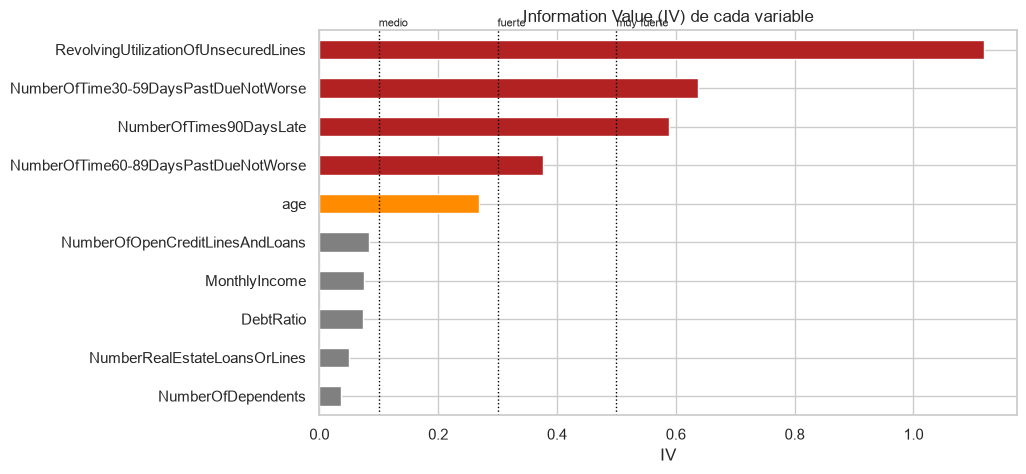

,IV
NumberOfDependents,0.036
NumberRealEstateLoansOrLines,0.049
DebtRatio,0.074
MonthlyIncome,0.076
NumberOfOpenCreditLinesAndLoans,0.083
age,0.269
NumberOfTime60-89DaysPastDueNotWorse,0.376
NumberOfTimes90DaysLate,0.588
NumberOfTime30-59DaysPastDueNotWorse,0.638
RevolvingUtilizationOfUnsecuredLines,1.118


In [44]:
datos_iv = train[FEATS].copy()
datos_iv[LATE] = datos_iv[LATE].where(datos_iv[LATE] < 96)  # 96/98 → rango propio
iv_variables = pd.Series(
    {col: information_value(datos_iv[col], train[TARGET]) for col in FEATS},
    name="IV",
).sort_values()

colores = ["firebrick" if v > 0.3 else "darkorange" if v > 0.1 else "gray"
           for v in iv_variables]
ax = iv_variables.plot(kind="barh", figsize=(9, 5), color=colores)
for umbral, texto in [(0.1, "medio"), (0.3, "fuerte"), (0.5, "muy fuerte")]:
    ax.axvline(umbral, color="black", ls=":", lw=1)
    ax.text(umbral, len(iv_variables) - 0.4, texto, fontsize=8)
ax.set_title("Information Value (IV) de cada variable")
ax.set_xlabel("IV")
plt.show()
iv_variables.round(3).to_frame()

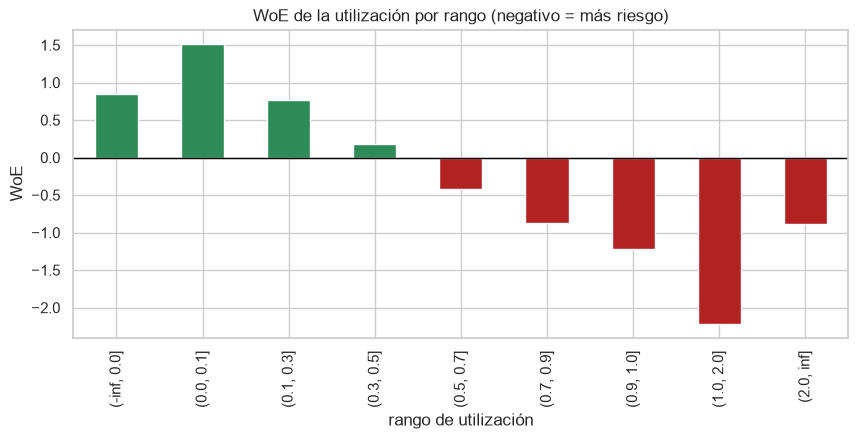

In [45]:
# WoE por rango de la utilización: así se ve la relación no lineal
rangos_util_woe = pd.cut(
    train["RevolvingUtilizationOfUnsecuredLines"],
    [-np.inf, 0, 0.1, 0.3, 0.5, 0.7, 0.9, 1, 2, np.inf],
)
conteos_util = pd.crosstab(rangos_util_woe, train[TARGET]) + 0.5
woe_util = np.log(
    (conteos_util[0] / conteos_util[0].sum()) / (conteos_util[1] / conteos_util[1].sum())
)
ax = woe_util.plot(kind="bar", figsize=(10, 4),
                   color=["firebrick" if w < 0 else "seagreen" for w in woe_util])
ax.axhline(0, color="black", lw=1)
ax.set_title("WoE de la utilización por rango (negativo = más riesgo)")
ax.set_xlabel("rango de utilización")
ax.set_ylabel("WoE")
plt.show()

**Lectura:**
- Cuatro variables concentran la señal: **utilización** y los **tres
  atrasos** (IV > 0.3). La edad tiene señal media. Ingreso, `DebtRatio`,
  líneas, hipotecas y dependientes son débiles por sí solas.
- El IV de la utilización (> 1) es muy alto. Aquí no es fuga de datos: el
  riesgo crece de forma muy marcada con la utilización, como muestra la
  sección 10.4.
- El WoE muestra la **curva** que una regresión logística con la variable
  cruda no puede capturar. El riesgo sube hasta 1–2 (WoE −2.2) y cambia de
  tendencia después. También se dobla en el extremo bajo: utilización
  exactamente 0 (WoE 0.8) es menos segura que 0–0.1 (WoE 1.5). WoE convierte
  esa curva en una relación lineal.

**Ventajas para el modelo:**
- **Resuelve atípicos y faltantes:** el faltante se vuelve un rango más, con
  su propio WoE.
- **Capta relaciones no lineales.**
- **Da una selección de variables justificable** con el IV.
- **Es fácil de explicar.**

En el notebook 03 se usa un codificador propio (`WoEEncoder`, con cortes
por cuantiles) para no agregar dependencias; `optbinning`, que busca cortes
óptimos y monótonos, queda como mejora posible. Los cortes y el WoE se
aprenden **dentro de cada pliegue**, porque usan la variable objetivo.

#### b) Ingreso disponible (capacidad de pago)
`ingreso disponible = ingreso − monto mensual de deuda`: lo que le queda al
cliente después de pagar sus deudas.

,IV (clientes con ingreso > 0)
MonthlyIncome,0.088
DebtRatio,0.083
monto de deuda,0.035
ingreso disponible,0.161


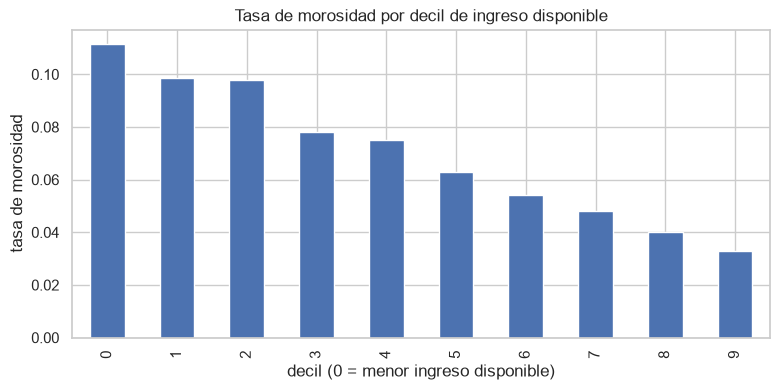

In [46]:
capacidad = train[train["MonthlyIncome"] > 0].copy()
capacidad["monto_deuda"] = capacidad["DebtRatio"] * capacidad["MonthlyIncome"]
capacidad["ingreso_disponible"] = capacidad["MonthlyIncome"] - capacidad["monto_deuda"]

iv_capacidad = pd.Series(
    {
        "MonthlyIncome": information_value(capacidad["MonthlyIncome"], capacidad[TARGET]),
        "DebtRatio": information_value(capacidad["DebtRatio"], capacidad[TARGET]),
        "monto de deuda": information_value(capacidad["monto_deuda"], capacidad[TARGET]),
        "ingreso disponible": information_value(
            capacidad["ingreso_disponible"], capacidad[TARGET]
        ),
    },
    name="IV (clientes con ingreso > 0)",
)
display(iv_capacidad.round(3).to_frame())

deciles_disp = pd.qcut(capacidad["ingreso_disponible"].rank(method="first"), 10, labels=False)
ax = capacidad.groupby(deciles_disp)[TARGET].mean().plot(kind="bar", figsize=(9, 4))
ax.set_title("Tasa de morosidad por decil de ingreso disponible")
ax.set_xlabel("decil (0 = menor ingreso disponible)")
ax.set_ylabel("tasa de morosidad")
plt.show()

**Lectura:** el ingreso disponible tiene un **IV de 0.161, casi el doble que
el ingreso solo (0.088)** y mucho más que el monto de deuda (0.035). Además, la
relación es **limpia y monótona**: la morosidad baja de 11.1 % en el decil con
menos ingreso disponible a 3.3 % en el de más. Es la variable nueva con más
señal de este análisis.

Para clientes sin ingreso no se puede calcular directamente: se usa el
ingreso imputado (⭐ C o 🔷 B) menos el monto de deuda, con el indicador
`income_missing`.

#### c) Imputación del ingreso con un modelo y su trampa
En lugar de medianas, un modelo predice el ingreso con las demás
variables. Se mide con el mismo protocolo de la sección 10.3 d.

In [47]:
from sklearn.ensemble import HistGradientBoostingRegressor

vars_con_ratio = [c for c in FEATS if c != "MonthlyIncome"]
vars_con_monto = [c for c in vars_con_ratio if c != "DebtRatio"] + ["monto_deuda"]
error_modelos = {}
for nombre, columnas in [
    ("modelo con DebtRatio", vars_con_ratio),
    ("modelo con monto de deuda (sin DebtRatio)", vars_con_monto),
]:
    modelo = HistGradientBoostingRegressor(random_state=42)
    modelo.fit(ajuste[columnas], np.log1p(ajuste["MonthlyIncome"]))
    error_modelos[nombre] = float(np.abs(log_real - modelo.predict(prueba[columnas])).mean())

comparacion_c = pd.concat(
    [
        comparacion["error (MAE en log)"],
        pd.Series(error_modelos, name="error (MAE en log)"),
    ]
).to_frame()
comparacion_c["mejora vs global (%)"] = (
    1 - comparacion_c["error (MAE en log)"] / comparacion_c["error (MAE en log)"].iloc[0]
) * 100
comparacion_c.round(3)

,error (MAE en log),mejora vs global (%)
mediana global,0.577,0.000
mediana por grupo de edad,0.543,5.915
edad + utilización de la línea de crédito (quintil),0.538,6.690
"edad + dependientes (0, 1, 2+)",0.535,7.264
edad + n.º de líneas de crédito abiertas (quintil),0.527,8.572
⭐ C: edad + líneas de crédito + dependientes,0.521,9.656
A (descartada): edad + n.º de créditos hipotecarios,0.515,10.611
mediana por decil del monto de deuda,0.498,13.678
🔷 B (alternativa): edad + decil del monto de deuda,0.484,16.125
modelo con DebtRatio,0.363,37.099


**Lectura: la trampa.** El modelo con `DebtRatio` parece excelente (37.1 %
de mejora), pero **no sirve**:
- En los clientes **con** ingreso, `DebtRatio` es una razón (deuda /
  ingreso). Si el modelo también ve el resto del perfil, aprende a
  "despejar" el ingreso de esa razón.
- En los clientes **sin** ingreso, `DebtRatio` es un monto, no una razón. Esa
  relación no existe, y la predicción fallaría justo donde se necesita.

La versión correcta usa el monto de deuda, que significa lo mismo en ambos
grupos. Logra 17.9 %, apenas mejor que 🔷 B (16.1 %), y es más difícil de
explicar y de mantener. **No es prioritaria.**

#### d) Curvas suaves (*splines*) para la regresión logística
`SplineTransformer` de `scikit-learn` convierte una variable en varias
curvas suaves, para que la regresión logística capte relaciones no lineales
sin discretizar. Candidatas: **utilización** (sube y cambia de tendencia) y
**edad** (el riesgo baja de forma continua). Es la alternativa a WoE cuando
no se quiere agrupar en rangos.

#### e) Indicadores de perfil

In [48]:
sin_atrasos = train[LATE].where(train[LATE] < 96, 0).sum(axis=1) == 0
perfiles = {
    "utilización = 0": train["RevolvingUtilizationOfUnsecuredLines"] == 0,
    "expediente delgado (sin atrasos, sin utilización, ≤ 1 línea)": (
        sin_atrasos
        & (train["RevolvingUtilizationOfUnsecuredLines"] == 0)
        & (train["NumberOfOpenCreditLinesAndLoans"] <= 1)
    ),
}
pd.DataFrame(
    {
        "clientes": {k: int(m.sum()) for k, m in perfiles.items()},
        "tasa de morosidad": {k: train.loc[m, TARGET].mean() for k, m in perfiles.items()},
        "tasa del resto": {k: train.loc[~m, TARGET].mean() for k, m in perfiles.items()},
    }
).round(4)

,clientes,tasa de morosidad,tasa del resto
utilización = 0,7652,0.0297,0.0698
"expediente delgado (sin atrasos, sin utilización, ≤ 1 línea)",316,0.0158,0.0670


**Lectura:** quien no usa sus líneas de crédito tiene menos de la mitad del
riesgo promedio, y el expediente delgado aún menos. Es el mismo tipo de
perfil de los registros con contenido repetido (sección 1). Son
indicadores baratos de construir y fáciles de interpretar.

#### Resumen de alternativas adicionales

| Alternativa | Evidencia | Recomendación |
| --- | --- | --- |
| **a) WoE / IV** | 4 variables con IV > 0.3; captura la curva de la utilización | ✅ **Prioridad alta:** enfoque paralelo para la regresión logística |
| **b) Ingreso disponible** | IV casi el doble que el del ingreso | ✅ **Prioridad alta:** variable nueva |
| c) Imputación con modelo | Con monto de deuda apenas mejora a 🔷 B | ❌ No prioritaria |
| d) *Splines* | Relaciones no lineales en utilización y edad | Experimento secundario |
| e) Indicadores de perfil | Utilización 0 y expediente delgado: menos de la mitad del riesgo | Experimento secundario (muy barato) |

### 10.9 Del EDA a la ingeniería de variables
Esta propuesta está implementada en `notebooks/03_ingenieria_variables_jae`
con el módulo `src/features/engineering_jae.py` (pruebas en
`tests/test_engineering_jae.py`). Es una propuesta independiente de
`02_features_separabilidad` y de `src/features/features.py`, elaborados
por otro integrante del equipo, para comparar hallazgos después.

| Decisión del EDA | Sección | En el módulo |
| --- | --- | --- |
| Códigos 96/98 → `NaN` + indicador | 10.4 | `clean_raw`: `late_sentinel` |
| Edad < 18 → `NaN` | 10.4 | `clean_raw` |
| Indicadores de ingreso faltante, 0 y de relleno (= 1) | 10.3 e, 10.4 | `income_missing`, `income_zero`, `income_placeholder` |
| Recortes: utilización 2, atrasos 6, ingreso 25,000, líneas 24, hipotecas 5, dependientes 5 | 10.6 | `add_fixed_features` |
| `DebtRatio` separado en razón válida y monto de deuda | 10.3 b, e | `debt_ratio_valid`, `debt_amount` |
| ⭐ C: ingreso por edad + quintil de líneas + dependientes, con respaldo y mínimo de 30 clientes | 10.3 d | `GroupMedianImputer` → `income_imp_age_lines_dep` |
| 🔷 B: ingreso por edad + decil del monto de deuda | 10.3 d | `GroupMedianImputer` → `income_imp_age_debt` |
| A: edad + hipotecas (descartada) | 10.3 d | Solo como experimento de referencia |
| Ingreso 0 y de relleno fuera del ajuste de las medianas | 10.3 e | `fit_above` del imputador |
| Dependientes: mediana por grupo de edad | 10.6 | `GroupMedianImputer` |
| Ingreso disponible | 10.8 b | `disposable_<ingreso>` |
| Ingreso por dependiente | 10.3 f | `per_dependent_<ingreso>` |
| Indicadores de perfil | 10.8 e | `util_zero`, `thin_file` |
| WoE / IV y *splines* | 10.8 a, d | `WoEEncoder` propio (sin `optbinning`) y `SplineTransformer` |
| `log1p` + `StandardScaler`; alternativas `RobustScaler` y `QuantileTransformer` | 10.5 | `build_preprocessor` |

**Experimentos del notebook 03** (validación cruzada estratificada de 5
pliegues, semilla 42, AUC-ROC; todo lo aprendido se ajusta dentro del
pliegue):
- Ingreso: solo ⭐ C, solo 🔷 B o **ambas variables** (con mediana global y
  A como referencia).
- Escalado: `StandardScaler` contra `RobustScaler` contra
  `QuantileTransformer`.
- Atrasos: conteo transformado contra binarizado.
- Representación para la regresión logística: variables escaladas contra
  WoE contra *splines*.
- Con y sin ingreso disponible, ingreso por dependiente e indicadores de
  perfil.
- Modelos: regresión logística y un modelo de árboles.

**Nota:** en este EDA las medianas de la sección 10.3 d se exploran con los
clientes de ingreso > 0. El módulo además deja fuera el ingreso = 1 (423
clientes), por lo que sus cifras difieren muy poco de las de aquí.

El detalle queda en `docs/plan_ingenieria_variables.md`.

## 11. Resumen y siguientes pasos

| Hallazgo | Qué hacer después |
| --- | --- |
| Sin `Id` repetidos; 339 filas con mismo contenido y distinto `Id` | No se elimina nada; probar su efecto en validación cruzada |
| Perfiles idénticos con objetivo distinto | Se conservan; son ruido irreducible |
| Clase positiva muy minoritaria | Validación cruzada estratificada, AUC-ROC, `class_weight` |
| Faltantes en ingreso y dependientes (siempre juntos) | Ingreso: **dos variables imputadas**, ⭐ C (edad + líneas de crédito abiertas + dependientes) y 🔷 B (edad + decil de deuda); A descartada; dependientes: mediana por edad; todas con indicador (sección 10.3) |
| Ingreso muy disperso (CV 2.3, máximo 120 veces el p99) | Recortar a p99 + `log1p` (sección 10.2) |
| `DebtRatio` es un monto cuando falta el ingreso (siempre está informado) | Separar en razón válida y monto de deuda; el monto ayuda a inferir el ingreso |
| Monto de deuda: muy disperso (CV 2.1), relación en U con la morosidad | `log1p`; vale más combinado con el ingreso (sección 10.3 e) |
| Más dependientes, más riesgo (5.9 % → 10.1 %), sobre todo en jóvenes e ingresos bajos | Agregar ingreso por dependiente, `per_dependent_<ingreso>` (IV 0.125) (sección 10.3 f) |
| 423 clientes con ingreso = 1 (valor de relleno, no ingreso real) | Tratarlo como ingreso = 0: indicador propio (`income_placeholder`) y fuera del ajuste de la imputación |
| PCA: el jugo en los datos se reparte en varios componentes | Ver sección 10.7 |
| Utilización y atrasos concentran la señal (IV > 0.3) | WoE / IV como enfoque paralelo (sección 10.8) |
| Ingreso disponible: IV casi el doble que el ingreso | Variable nueva (sección 10.8) |
| Códigos 96/98 en variables de atraso | Tratarlos aparte (NaN + indicador) |
| Edad 0, utilización y DebtRatio extremos | Recortar a percentil alto o limpiar |
| Variables muy asimétricas | Recortar → `log1p` → `StandardScaler` para modelos lineales; árboles sin escalado |
| Atrasos previos son los más predictivos | Crear variables agregadas de atrasos |

**Plan de experimentos sugerido:**
1. Línea base: regresión logística con regularización (L1/L2) sobre datos limpios y escalados.
2. Modelos de árboles: Random Forest y Gradient Boosting (manejan asimetría y no linealidad).
3. Validación cruzada estratificada de 5 particiones, medida en AUC-ROC.
4. Selección de hiperparámetros con búsqueda (`GridSearchCV` / `RandomizedSearchCV`).
5. Comparar el efecto de cada decisión de limpieza y de variables nuevas.

**Importante:** las transformaciones (medianas, escalado) se ajustan solo con
los datos de entrenamiento de cada partición, para evitar fuga de datos.